In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from astroquery.jplhorizons import Horizons
from astropy.time import Time
from scipy.spatial.transform import Rotation

import collections
import struct

from construct import *

import sys
sys.path.append('../Tianwen')

import ccsds

plt.rcParams['figure.figsize'] = (7, 3.5)
plt.rcParams['figure.facecolor'] = 'w'

## AOS frames

MMX transmits CCSDS AOS frames. The spacecraft ID is 0xe4, which is [registered in SANA registry](https://sanaregistry.org/r/spacecraftid/?spacecraft=1405). Virtual channels 0, 1, 62 and 63 (only idle data are in use).

All the virtual channels contain an OCF carrying a CLCW. Virtual channel 63 contains zeros in most of the frame, including the virtual channel frame count, the M_PDU header and the payload.

In [2]:
CLCW = BitStruct(
    'control_word_type' / Flag,
    'clcw_version_number' / BitsInteger(2),
    'status_field' / BitsInteger(3),
    'cop_in_effect' / BitsInteger(2),
    'virtual_channel_identification' / BitsInteger(6),
    'rsvd_spare' / BitsInteger(2),
    'no_rf_avail' / Flag,
    'no_bit_lock' / Flag,
    'lock_out' / Flag,
    'wait' / Flag,
    'retransmit' / Flag,
    'farm_b_counter' / BitsInteger(2),
    'rsvd_spare2' / BitsInteger(1),
    'report_value' / BitsInteger(8)
)

AOSFrame = Struct(
    'primary_header' / ccsds.AOSPrimaryHeader,
    'm_pdu_header' / ccsds.M_PDU_Header,
    'm_pdu_packet_zone' / Bytes(1101),
    'ocf' / CLCW,
)

In [3]:
frame_size = 1113

def load_frames(filename):
    frames = np.fromfile(filename, dtype='uint8')
    return frames[:frames.size//frame_size*frame_size].reshape(-1, frame_size)

In [4]:
frames = load_frames('mmx_frames.u8')
frames.shape

(195362, 1113)

In [5]:
aos = [AOSFrame.parse(f) for f in frames]

In [6]:
[a.primary_header for a in aos[:10]]

[Container(transfer_frame_version_number=1, spacecraft_id=228, virtual_channel_id=0, virtual_channel_frame_count=2351720, replay_flag=False, vc_frame_count_usage_flag=False, rsvd_spare=0, vc_framecount_cycle=0),
 Container(transfer_frame_version_number=1, spacecraft_id=228, virtual_channel_id=0, virtual_channel_frame_count=2351721, replay_flag=False, vc_frame_count_usage_flag=False, rsvd_spare=0, vc_framecount_cycle=0),
 Container(transfer_frame_version_number=1, spacecraft_id=228, virtual_channel_id=0, virtual_channel_frame_count=2351722, replay_flag=False, vc_frame_count_usage_flag=False, rsvd_spare=0, vc_framecount_cycle=0),
 Container(transfer_frame_version_number=1, spacecraft_id=228, virtual_channel_id=63, virtual_channel_frame_count=0, replay_flag=False, vc_frame_count_usage_flag=False, rsvd_spare=0, vc_framecount_cycle=0),
 Container(transfer_frame_version_number=1, spacecraft_id=228, virtual_channel_id=0, virtual_channel_frame_count=2351723, replay_flag=False, vc_frame_count_u

In [7]:
collections.Counter([a.primary_header.transfer_frame_version_number for a in aos])

Counter({1: 195362})

In [8]:
collections.Counter([a.primary_header.spacecraft_id for a in aos])

Counter({228: 195362})

In [9]:
collections.Counter([a.primary_header.virtual_channel_id for a in aos])

Counter({0: 161761, 63: 22377, 1: 9516, 62: 1708})

In [10]:
collections.Counter([a.primary_header.replay_flag for a in aos])

Counter({False: 195362})

In [11]:
collections.Counter([a.primary_header.vc_frame_count_usage_flag for a in aos])

Counter({False: 195362})

In [12]:
collections.Counter([a.primary_header.rsvd_spare for a in aos])

Counter({0: 195362})

In [13]:
collections.Counter([a.primary_header.vc_framecount_cycle for a in aos])

Counter({0: 195362})

In [14]:
vcid = np.array([a.primary_header.virtual_channel_id for a in aos])
vcfc = np.array([a.primary_header.virtual_channel_frame_count for a in aos])

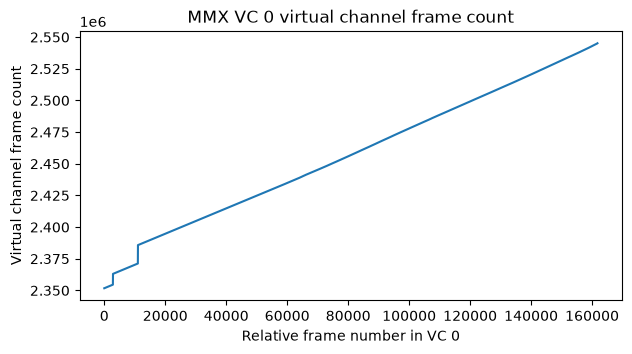

In [15]:
plt.plot(vcfc[vcid == 0])
plt.title('MMX VC 0 virtual channel frame count')
plt.xlabel('Relative frame number in VC 0')
plt.ylabel('Virtual channel frame count');

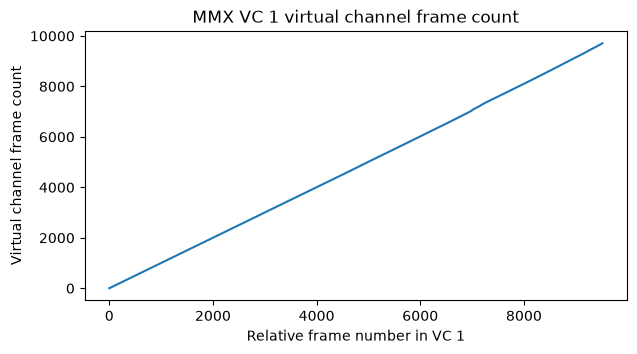

In [16]:
plt.plot(vcfc[vcid == 1])
plt.title('MMX VC 1 virtual channel frame count')
plt.xlabel('Relative frame number in VC 1')
plt.ylabel('Virtual channel frame count');

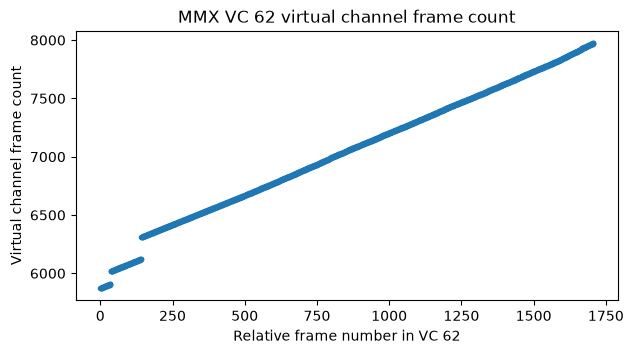

In [17]:
plt.plot(vcfc[vcid == 62], '.')
plt.title('MMX VC 62 virtual channel frame count')
plt.xlabel('Relative frame number in VC 62')
plt.ylabel('Virtual channel frame count');

In [18]:
assert np.all(vcfc[vcid == 63] == 0)

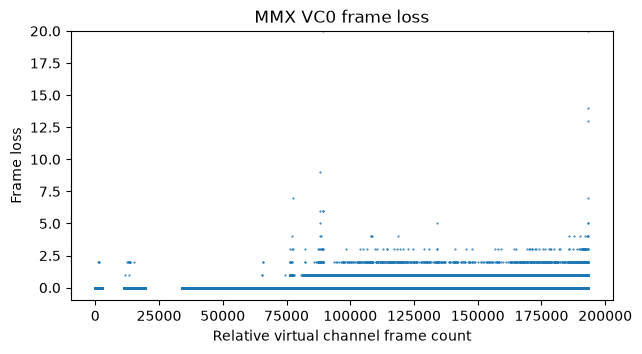

In [19]:
sel = vcid == 0
lim = 20
plt.plot(vcfc[sel][1:] - vcfc[sel][0], np.diff(vcfc[sel]) - 1, '.', markersize=1)
plt.ylim(-1, lim)
plt.title('MMX VC0 frame loss')
plt.xlabel('Relative virtual channel frame count')
plt.ylabel('Frame loss');

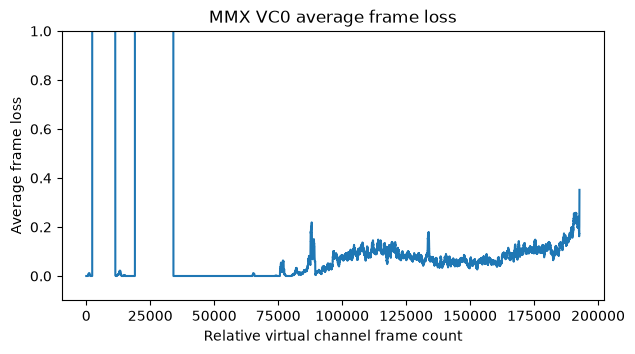

In [20]:
Navg = 512
plt.plot(vcfc[sel][1:-(Navg-1)] - vcfc[sel][0], np.convolve(np.diff(vcfc[sel]) - 1, np.ones(Navg) / Navg, mode='valid'))
plt.ylim(-0.1, 1.0)
plt.title('MMX VC0 average frame loss')
plt.xlabel('Relative virtual channel frame count')
plt.ylabel('Average frame loss');

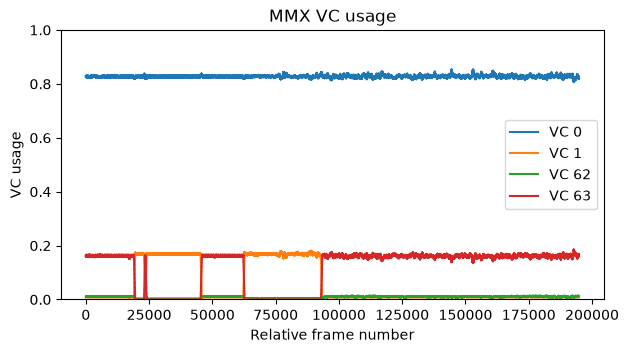

In [21]:
Navg = 512
for vc in [0, 1, 62, 63]:
    plt.plot(np.convolve(vcid == vc, np.ones(Navg) / Navg, mode='valid'), label=f'VC {vc}')
plt.ylim(0, 1)
plt.legend()
plt.title('MMX VC usage')
plt.xlabel('Relative frame number')
plt.ylabel('VC usage');

In [22]:
assert np.all(frames[vcid == 63][:, 2:-4] == 0)

In [23]:
clcw = [a.ocf for a in aos]
clcw[:10]

[Container(control_word_type=False, clcw_version_number=0, status_field=0, cop_in_effect=1, virtual_channel_identification=0, rsvd_spare=0, no_rf_avail=False, no_bit_lock=False, lock_out=False, wait=False, retransmit=False, farm_b_counter=2, rsvd_spare2=0, report_value=193),
 Container(control_word_type=False, clcw_version_number=0, status_field=0, cop_in_effect=1, virtual_channel_identification=0, rsvd_spare=0, no_rf_avail=False, no_bit_lock=False, lock_out=False, wait=False, retransmit=False, farm_b_counter=2, rsvd_spare2=0, report_value=193),
 Container(control_word_type=False, clcw_version_number=0, status_field=0, cop_in_effect=1, virtual_channel_identification=0, rsvd_spare=0, no_rf_avail=False, no_bit_lock=False, lock_out=False, wait=False, retransmit=False, farm_b_counter=2, rsvd_spare2=0, report_value=193),
 Container(control_word_type=False, clcw_version_number=0, status_field=0, cop_in_effect=1, virtual_channel_identification=0, rsvd_spare=0, no_rf_avail=False, no_bit_lock=F

In [24]:
collections.Counter([(c.control_word_type, c.clcw_version_number, c.status_field, c.cop_in_effect,
                      c.virtual_channel_identification, c.rsvd_spare, c.no_rf_avail, c.no_bit_lock, c.lock_out,
                      c.wait, c.retransmit, c.farm_b_counter, c.rsvd_spare2)
                     for c in clcw])

Counter({(False,
          0,
          0,
          1,
          0,
          0,
          False,
          False,
          False,
          False,
          False,
          2,
          0): 195362})

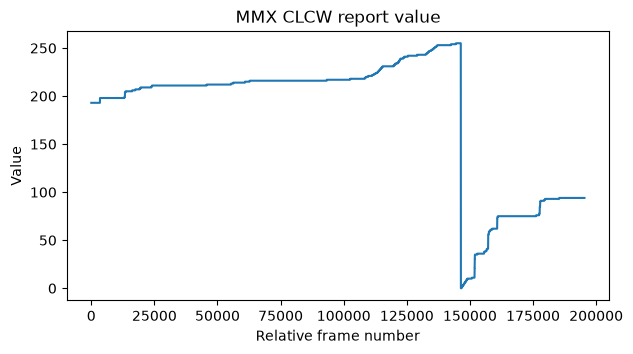

In [25]:
plt.plot([c.report_value for c in clcw])
plt.title('MMX CLCW report value')
plt.xlabel('Relative frame number')
plt.ylabel('Value');

## VC 0

Virtual channel 0 contains CCSDS Space Packets using M_PDU. All the space packets have an secondary heaer, which is probably 8 bytes long. The first 5 bytes of the header are a CCSDS CUC time code with explicit P-field and an epoch of 2013-01-01T00:00:00. The next byte in the header is always a 0, the following byte varies, and the last byte is always `0x60`. The first byte after the secondary header indicates the packet type (within each APID). There are no idle space packets. There are only a few APIDs in use.

In [26]:
vc0_packets = list(ccsds.extract_space_packets(aos, 0xe4, 0))

/home/daniel/contracting/MMX/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 228 VC 0] Broken stream. Last frame count 2352953, current frame count 2352956
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {frame_count_new}')
/home/daniel/contracting/MMX/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 228 VC 0] Broken stream. Last frame count 2353002, current frame count 2353005
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {frame_count_new}')
/home/daniel/contracting/MMX/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 228 VC 0] Broken stream. Last frame count 2353227, current frame count 2353230
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {fr

In [27]:
vc0_headers = [ccsds.SpacePacketPrimaryHeader.parse(p) for p in vc0_packets]

In [28]:
vc0_headers[:10]

[Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=57, sequence_flags=3, packet_sequence_count_or_name=13164, data_length=471),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=57, sequence_flags=3, packet_sequence_count_or_name=13165, data_length=364),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=61, sequence_flags=3, packet_sequence_count_or_name=13175, data_length=968),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=57, sequence_flags=3, packet_sequence_count_or_name=13166, data_length=375),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=57, sequence_flags=3, packet_sequence_count_or_name=13167, data_length=292),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=57, sequence_flags=3, packet_sequence_count_or_name=13168, data_length=249),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=61, se

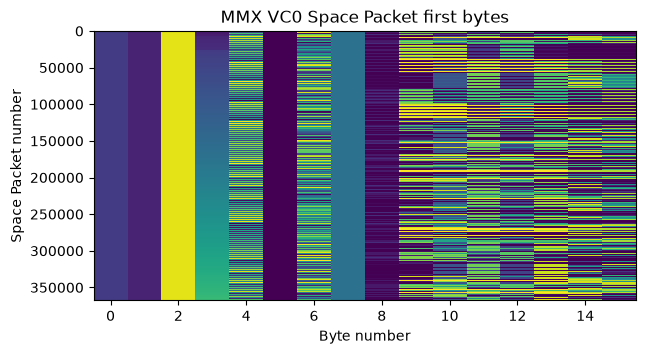

In [29]:
plt.imshow(np.array([np.frombuffer(p[6:6+16], 'uint8') for p in vc0_packets]), aspect='auto', interpolation='none');
plt.title('MMX VC0 Space Packet first bytes')
plt.ylabel('Space Packet number')
plt.xlabel('Byte number');

In [30]:
# P-field: 0b00101100
# extension = 0
# time code identification = 010 agency-defined epoch
# number of octects of basic time unit minus one 11 = 3
# number of octects of fractional time unit = 0
assert np.all(np.array([p[ccsds.SpacePacketPrimaryHeader.sizeof()] for p in vc0_packets]) == 0b00101100)

In [31]:
assert np.all(np.array([p[ccsds.SpacePacketPrimaryHeader.sizeof()+5] for p in vc0_packets]) == 0)

In [32]:
assert all(p[ccsds.SpacePacketPrimaryHeader.sizeof()+7] == (0x65 if h.APID == 817 else 0x60)
           for (h, p) in zip(vc0_headers, vc0_packets))

In [33]:
vc0_apids = collections.Counter([p.APID for p in vc0_headers])
vc0_apids

Counter({57: 164199, 49: 98687, 61: 96481, 53: 8234, 817: 248})

In [34]:
{apid: collections.Counter([p.data_length for p in vc0_headers if p.APID == apid])
 for apid in vc0_apids}

{57: Counter({249: 32946,
          292: 32926,
          364: 32812,
          375: 32800,
          471: 32707,
          1005: 7,
          173: 1}),
 61: Counter({968: 64016, 568: 32465}),
 49: Counter({249: 65928, 441: 32759}),
 53: Counter({249: 8234}),
 817: Counter({141: 233, 81: 13, 133: 2})}

In [35]:
{apid: collections.Counter([(p[ccsds.SpacePacketPrimaryHeader.sizeof()+8], h.data_length)
                            for (h, p) in zip(vc0_headers, vc0_packets) if h.APID == apid])
 for apid in vc0_apids}

{57: Counter({(32, 249): 32946,
          (17, 292): 32926,
          (16, 364): 32812,
          (18, 375): 32800,
          (0, 471): 32707,
          (48, 1005): 1,
          (49, 1005): 1,
          (50, 1005): 1,
          (51, 1005): 1,
          (52, 1005): 1,
          (53, 1005): 1,
          (54, 1005): 1,
          (55, 173): 1}),
 61: Counter({(5, 568): 32465, (0, 968): 32066, (1, 968): 31950}),
 49: Counter({(2, 249): 32985, (0, 249): 32943, (1, 441): 32759}),
 53: Counter({(0, 249): 8234}),
 817: Counter({(17, 141): 233, (20, 81): 13, (17, 133): 2})}

In [36]:
{apid: collections.Counter(np.diff([p.packet_sequence_count_or_name for p in vc0_headers if p.APID == apid]))
 for apid in vc0_apids}

{57: Counter({np.int64(1): 158732,
          np.int64(3): 2298,
          np.int64(2): 1602,
          np.int64(4): 1142,
          np.int64(6): 198,
          np.int64(5): 142,
          np.int64(7): 20,
          np.int64(8): 17,
          np.int64(-16383): 9,
          np.int64(9): 8,
          np.int64(11): 3,
          np.int64(-16381): 2,
          np.int64(13): 2,
          np.int64(-7632): 1,
          np.int64(14964): 1,
          np.int64(10): 1,
          np.int64(21): 1,
          np.int64(-16040): 1,
          np.int64(16041): 1,
          np.int64(-16044): 1,
          np.int64(16045): 1,
          np.int64(-16048): 1,
          np.int64(16051): 1,
          np.int64(-16052): 1,
          np.int64(16053): 1,
          np.int64(-16056): 1,
          np.int64(16057): 1,
          np.int64(-16060): 1,
          np.int64(16061): 1,
          np.int64(-16064): 1,
          np.int64(16065): 1,
          np.int64(-16068): 1,
          np.int64(16070): 1,
          np.int64(24): 

In [37]:
def vc0_payloads_by_apid(apid, packet_type=None):
    return [p[ccsds.SpacePacketPrimaryHeader.sizeof() + 8:] for (h, p) in zip(vc0_headers, vc0_packets)
            if h.APID == apid and (packet_type is None or p[ccsds.SpacePacketPrimaryHeader.sizeof()+8] == packet_type)]

def vc0_array_by_apid(apid, packet_type):
    return np.array([np.frombuffer(p, 'uint8') for p in vc0_payloads_by_apid(apid, packet_type)])

def vc0_plot_apid(apid, packet_type, *, vmax=255, byte_sel=None):
    a = vc0_array_by_apid(apid, packet_type)
    if len(a) == 0:
        return
    plt.figure(figsize=(10, 4))
    if byte_sel is not None:
        a = a[:, byte_sel]
    plt.imshow(a, aspect='auto', interpolation='None', vmin=0, vmax=vmax)
    plt.title(f'MMX VC0 APID {apid} packet type 0x{packet_type:02x}')
    plt.ylabel('Packet number')
    plt.xlabel('Payload byte number')

In [38]:
vc0_secondary_headers = np.array([np.frombuffer(p[ccsds.SpacePacketPrimaryHeader.sizeof():][1:5], 'uint8') for p in vc0_packets])
vc0_packet_timestamps = ((vc0_secondary_headers.view('uint32').byteswap().ravel() * 1e9) * np.timedelta64(1, 'ns')
                     + np.datetime64('2013-01-01T00:00:00'))
vc0_apid_timestamps = {apid: vc0_packet_timestamps[np.array([h.APID for h in vc0_headers]) == apid] for apid in vc0_apids}

def vc0_apid_packet_type_timestamps(apid, packet_type):
    return vc0_packet_timestamps[
        np.array([(h.APID, p[ccsds.SpacePacketPrimaryHeader.sizeof()+8]) == (apid, packet_type)
                  for (h, p) in zip(vc0_headers, vc0_packets)])]

In [39]:
vc0_packet_timestamps[0], vc0_packet_timestamps[-1]

(np.datetime64('2026-10-20T09:46:42.000000000'),
 np.datetime64('2026-10-20T20:51:51.000000000'))

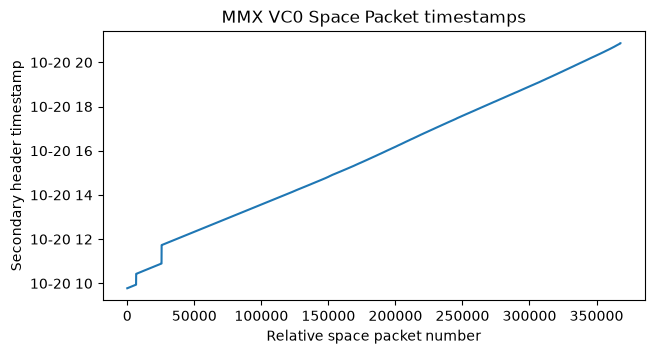

In [40]:
plt.plot(vc0_packet_timestamps)
plt.title('MMX VC0 Space Packet timestamps')
plt.ylabel('Secondary header timestamp')
plt.xlabel('Relative space packet number');

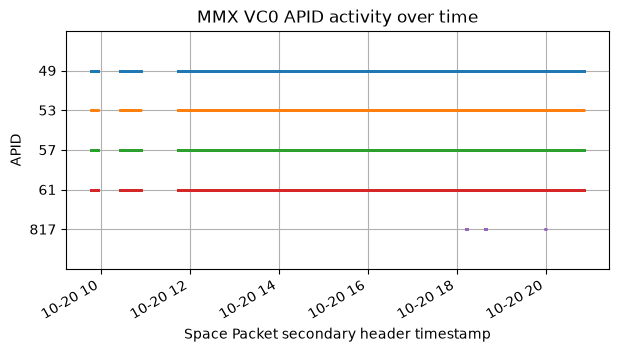

In [41]:
for k, apid in enumerate(sorted(vc0_apids)):
    ts = vc0_apid_timestamps[apid]
    plt.plot(ts, len(ts) * [-k], '.', color=f'C{k}', markersize=1)
plt.yticks(-np.arange(len(vc0_apids)), [str(a) for a in sorted(vc0_apids)])
plt.ylim(-len(vc0_apids), 1)
plt.grid()
plt.ylabel('APID')
plt.xlabel('Space Packet secondary header timestamp')
plt.title('MMX VC0 APID activity over time')
plt.gcf().autofmt_xdate();

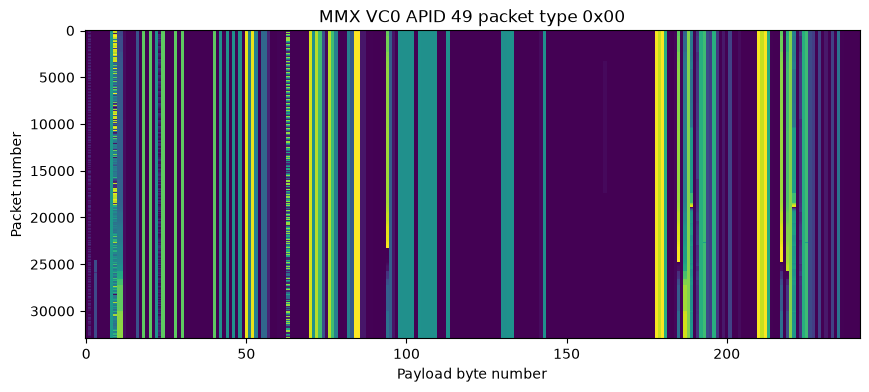

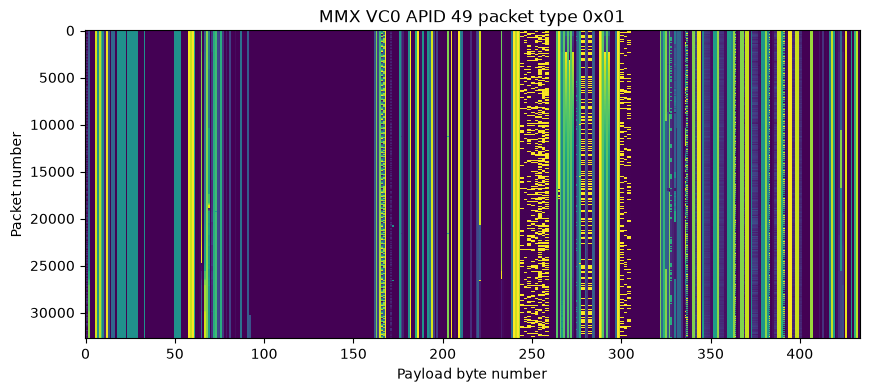

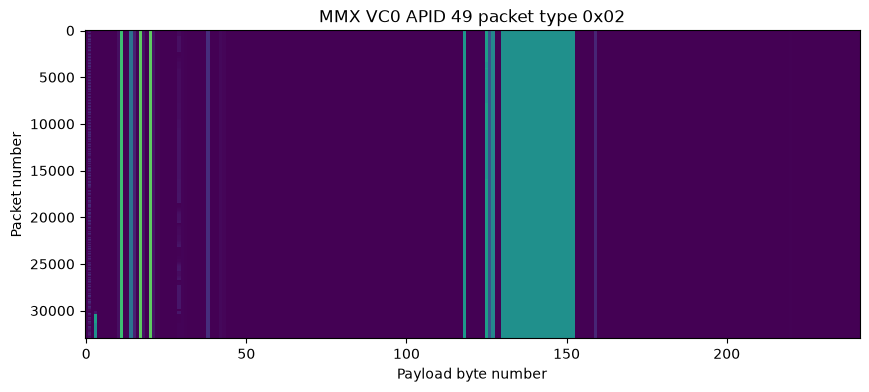

In [42]:
for packet_type in range(3):
    vc0_plot_apid(49, packet_type)

In [43]:
apid49_f64_timestamps = vc0_array_by_apid(49, 1)[:, 162:][:, :8].view('float64').byteswap().ravel()
apid49_f64_timestamps = (apid49_f64_timestamps * 1e9) * np.timedelta64(1, 'ns') + np.datetime64('2000-01-01T12:00:00')

In [44]:
timestamp_diff = (apid49_f64_timestamps - vc0_apid_packet_type_timestamps(49, 1)) / np.timedelta64(1, 's')
assert np.all(timestamp_diff == timestamp_diff[0])
timestamp_diff[0]

np.float64(34.68746944)

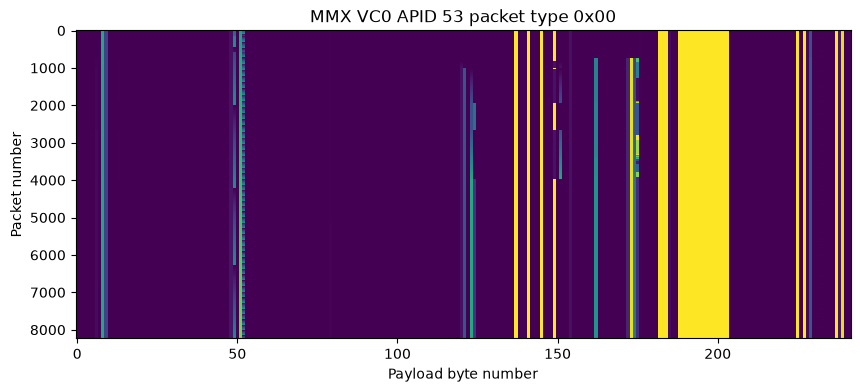

In [45]:
vc0_plot_apid(53, 0)

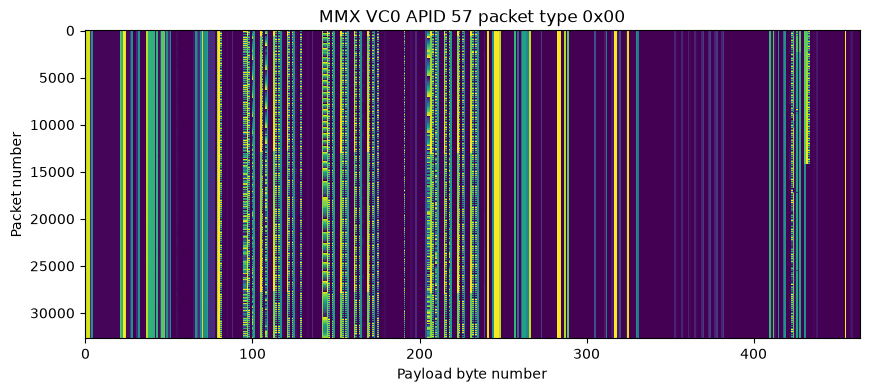

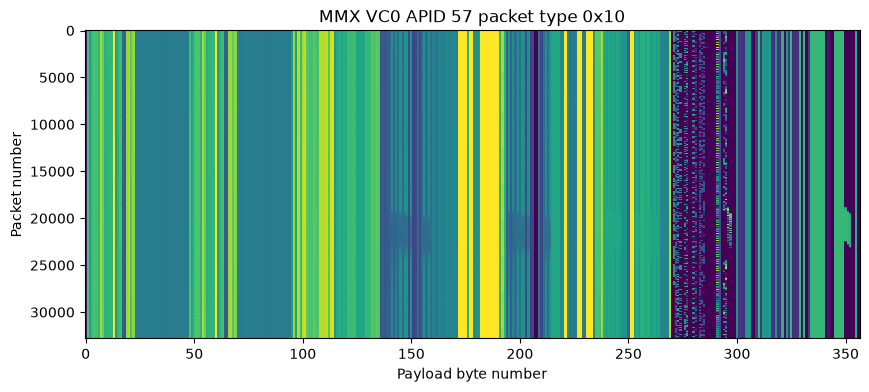

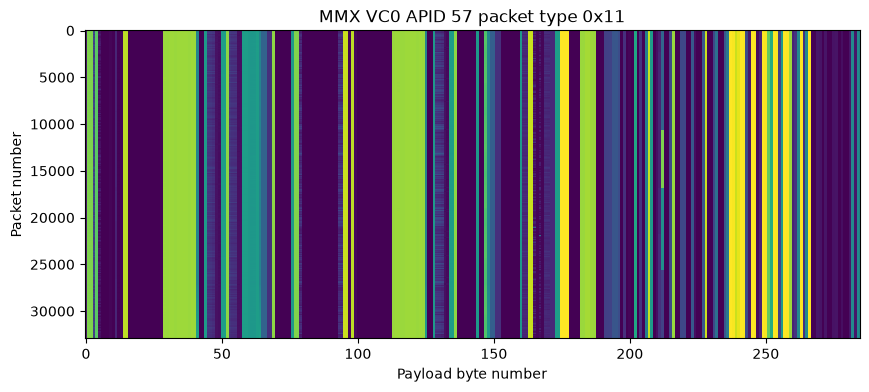

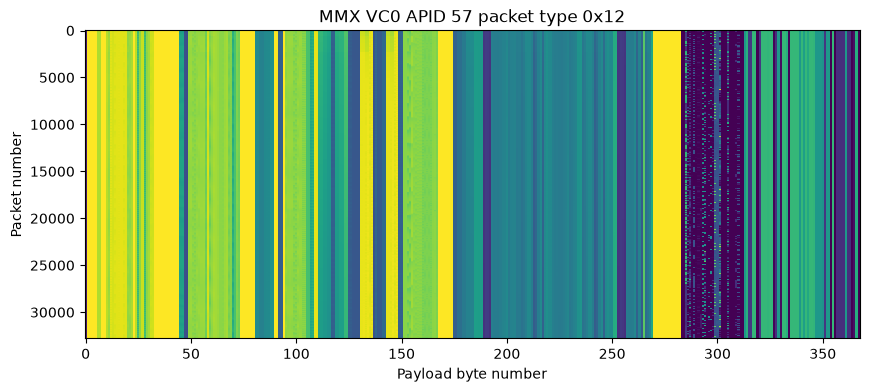

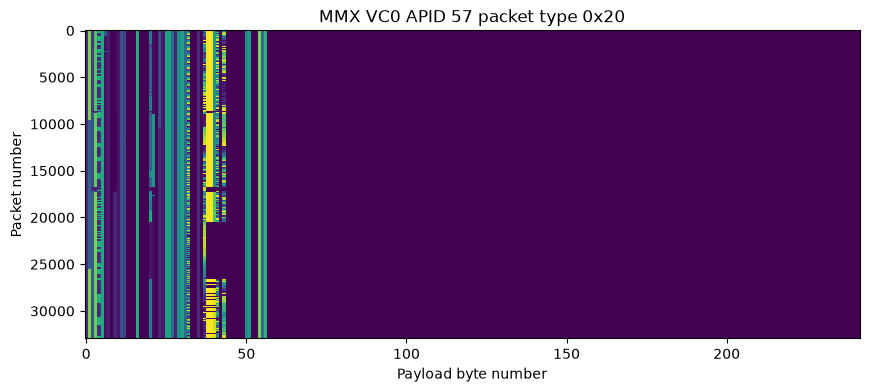

In [46]:
for packet_type in [0, 16, 17, 18, 32]:
    vc0_plot_apid(57, packet_type)

In [47]:
for packet_type in [48, 49, 50, 51, 52, 53, 54, 55]:
    print([a.hex() for a in vc0_payloads_by_apid(57, packet_type)])
    print()

['3040000418649a7373997272015c00bc0203003a00a5bdbdbdb3b3b301e740b10000800000cbdcdcdcd4d4d4022a40b40000800000e5ededede7e7e702da40670200003d00f2dcdcdcd4d4d4043d40ba0000800000f5cdcdcdc3c3c302da40600200003f00d99090908d8d8d02da406d0200004000bacdcdcdc3c3c3028a40bd0000800000d9e9e9e9e2e2e2039840bf0000800000f2dcdcdcd3d3d3096040720200004300e1efefefe9e9e9025840730200004400f5f8f8f8f4f4f4054840c40000800000fdafafafa0a0a005dc40e40200800000fa6c6c6c6b6b6b019d40770200004700816c6c6c6b6b6b01ee40c70000800000817373737272720463407a0200004900786c6c6c6b6b6b074c407b0200004a008b6c6c6c6b6b6b076b40cb00008000008b6c6c6c6b6b6b05e6407f0200004c008b6c6c6c6b6b6b03f740cf00008000008b6c6c6c6b6b6b06c840a30200004e008b6c6c6c6b6b6b06c440d300008000008b6c6c6c6b6b6b0a4840a702000050008b6c6c6c6b6b6b053c40d700008000008b6c6c6c6b6b6b082940ab02000052008b6c6c6c6b6b6b0ab840db00008000008b6e6e6e6f6f6f1770008c02010054ff6c7878787979790fa0005d02018000ff6c00000000000000000000000080000000dcdcdcd4d4d4022a40b00000800000e5bdbdbdb3b3b301e74063020000

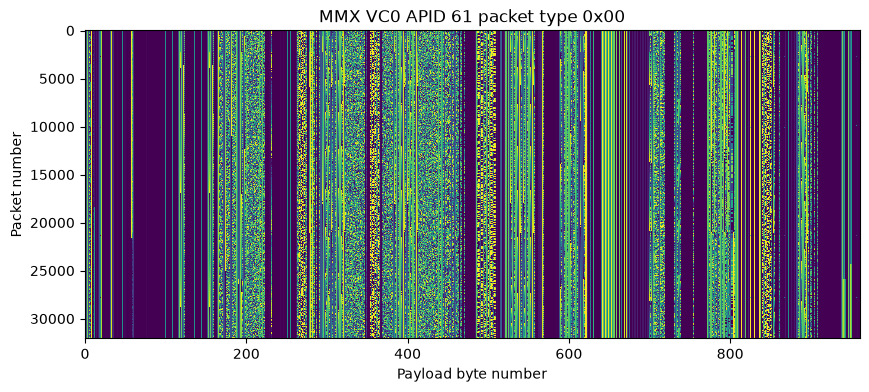

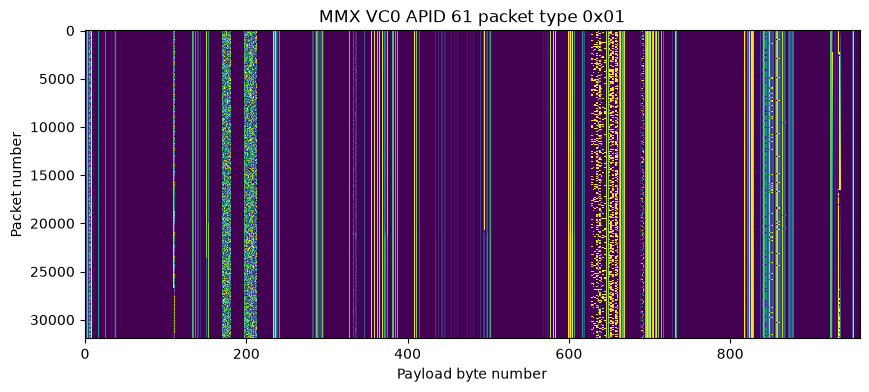

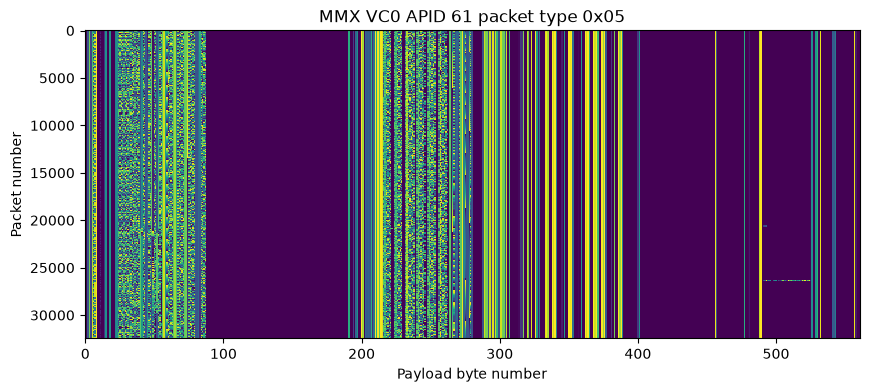

In [48]:
for packet_type in [0, 1, 5]:
    vc0_plot_apid(61, packet_type)

In [49]:
apid61_f64_timestamps = vc0_array_by_apid(61, 0)[:, 2:][:, :8].view('float64').byteswap().ravel()
apid61_f64_timestamps = (apid61_f64_timestamps * 1e9) * np.timedelta64(1, 'ns') + np.datetime64('2000-01-01T12:00:00')
apid61_f64_timestamps[:3]

array(['2026-10-20T09:47:18.124969472', '2026-10-20T09:47:19.124969472',
       '2026-10-20T09:47:20.124969472'], dtype='datetime64[ns]')

In [50]:
state_vectors_sun = Horizons(
    id='MMX', location='@sun',
    epochs={'start': '2026-10-19T20:30:00', 'stop': '2026-10-20T21:00:00', 'step': '88200'}
).vectors(refplane='earth')
for col in 'xyz':
    state_vectors_sun[col].convert_unit_to('m')
    state_vectors_sun[f'v{col}'].convert_unit_to('m/s')
state_vectors_sun_t = Time(state_vectors_sun['datetime_jd'], format='jd', scale='tdb').utc.datetime64

sun_xyz_interp = np.array([
    np.interp((apid61_f64_timestamps - state_vectors_sun_t[0]) / np.timedelta64(1, 's'),
              (state_vectors_sun_t - state_vectors_sun_t[0]) / np.timedelta64(1, 's'),
              state_vectors_sun[coord])
    for coord in 'xyz'])

sun_v_xyz_interp = np.array([
    np.interp((apid61_f64_timestamps - state_vectors_sun_t[0]) / np.timedelta64(1, 's'),
              (state_vectors_sun_t - state_vectors_sun_t[0]) / np.timedelta64(1, 's'),
              state_vectors_sun[f'v{coord}'])
    for coord in 'xyz'])

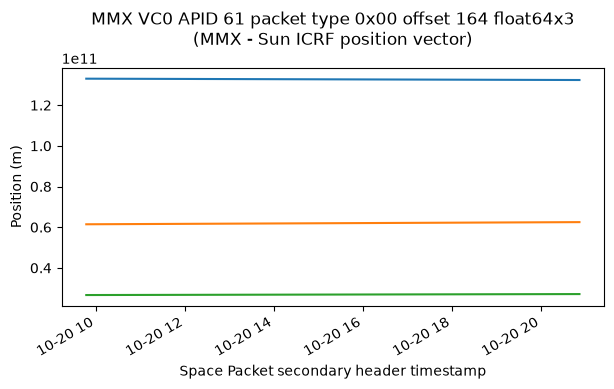

In [51]:
apid61_sun_r = vc0_array_by_apid(61, 0)[:, 164:][:, :3*8].view('float64').byteswap()
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_sun_r)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 164 float64x3\n(MMX - Sun ICRF position vector)')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Position (m)');

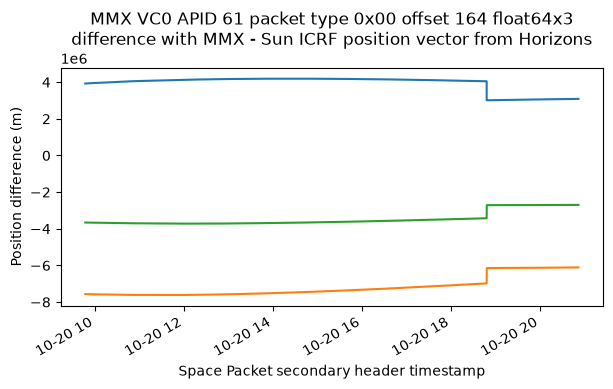

In [52]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0),
         apid61_sun_r - sun_xyz_interp.T)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 164 float64x3\ndifference with MMX - Sun ICRF position vector from Horizons')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Position difference (m)');

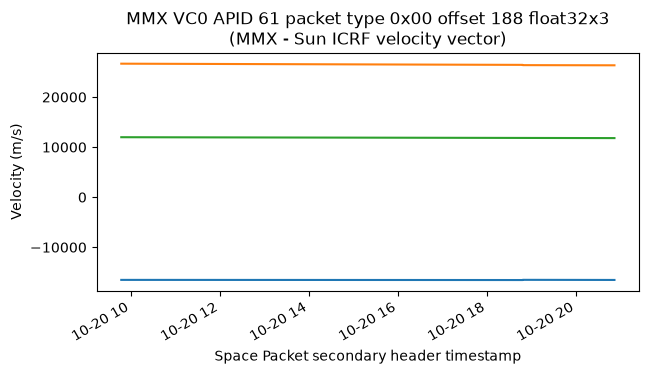

In [53]:
apid61_sun_v = vc0_array_by_apid(61, 0)[:, 188:][:, :4*3].view('float32').byteswap()
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_sun_v)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 188 float32x3\n(MMX - Sun ICRF velocity vector)')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Velocity (m/s)');

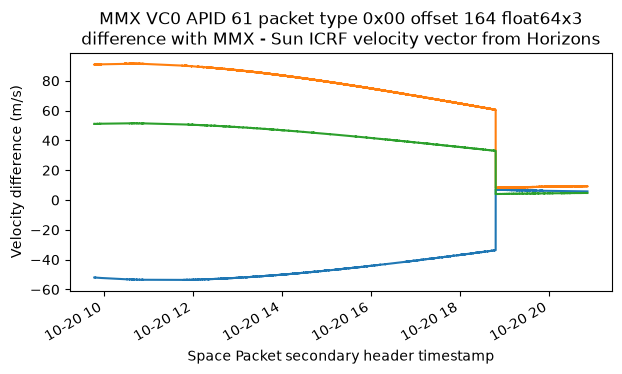

In [54]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0),
         apid61_sun_v - sun_v_xyz_interp.T)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 164 float64x3\ndifference with MMX - Sun ICRF velocity vector from Horizons')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Velocity difference (m/s)');

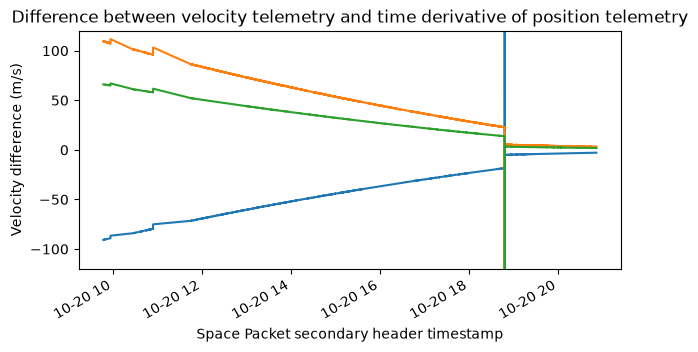

In [55]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0)[:-1],
         apid61_sun_v[:-1] - np.diff(apid61_sun_r, axis=0) / (np.diff(apid61_f64_timestamps) / np.timedelta64(1, 's'))[:, np.newaxis])
plt.ylim(-120, 120)
plt.gcf().autofmt_xdate()
plt.title('Difference between velocity telemetry and time derivative of position telemetry')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Velocity difference (m/s)');

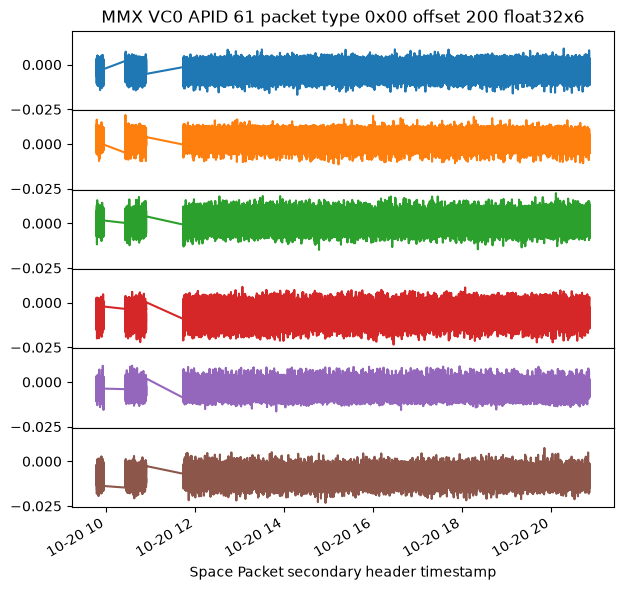

In [56]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 0),
                vc0_array_by_apid(61, 0)[:, 200+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x00 offset 200 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

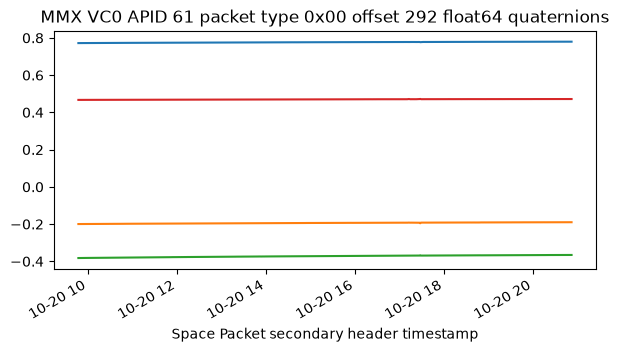

In [57]:
apid61_q0 = vc0_array_by_apid(61, 0)[:, 292:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q0**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q0)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 292 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

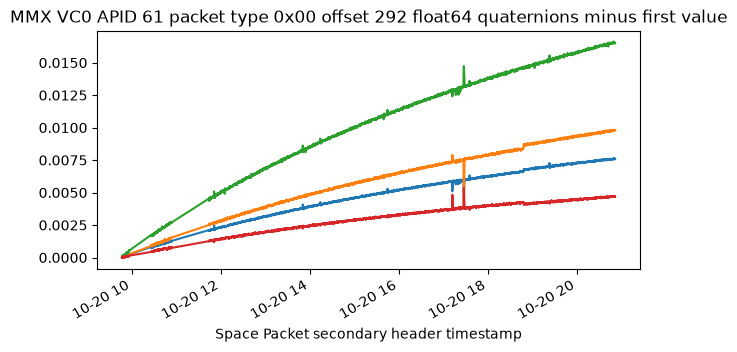

In [58]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q0 - apid61_q0[0])
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 292 float64 quaternions minus first value')
plt.xlabel('Space Packet secondary header timestamp');

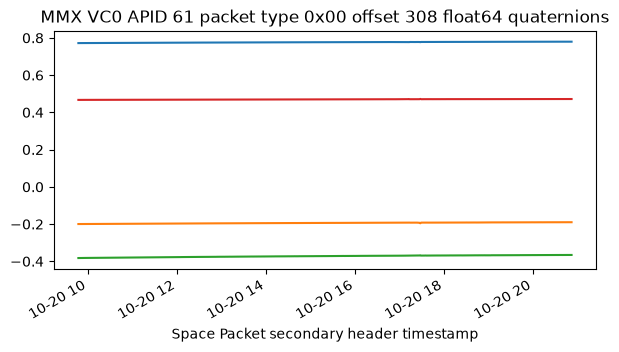

In [59]:
apid61_q1 = vc0_array_by_apid(61, 0)[:, 308:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q1**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q1)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 308 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

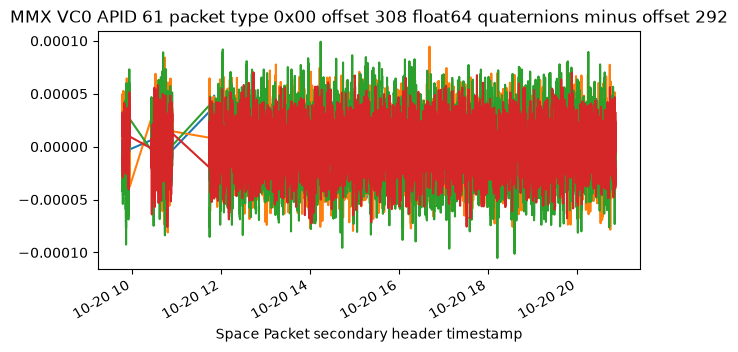

In [60]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q1 - apid61_q0)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 308 float64 quaternions minus offset 292')
plt.xlabel('Space Packet secondary header timestamp');

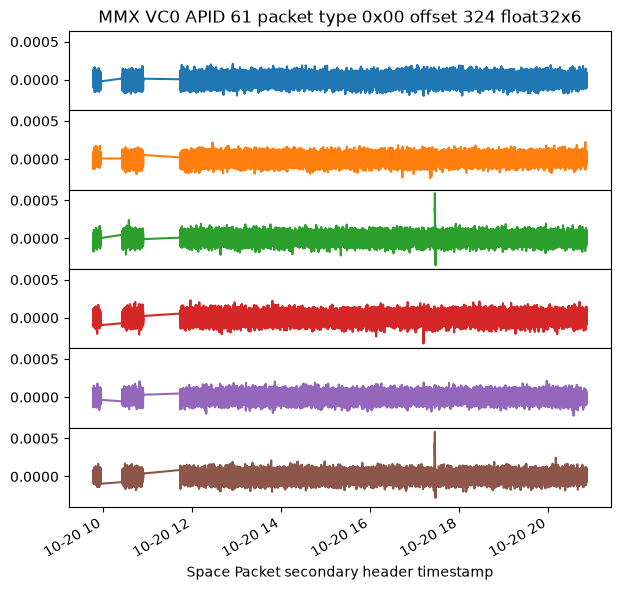

In [61]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 0),
                vc0_array_by_apid(61, 0)[:, 324+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x00 offset 324 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

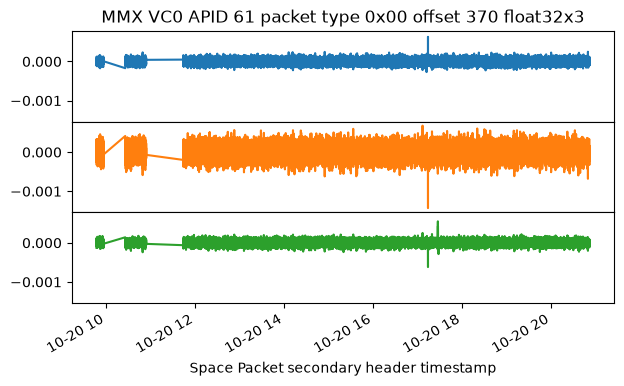

In [62]:
fig, axs = plt.subplots(3, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(3):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 0),
                vc0_array_by_apid(61, 0)[:, 370+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x00 offset 370 float32x3')
plt.xlabel('Space Packet secondary header timestamp');

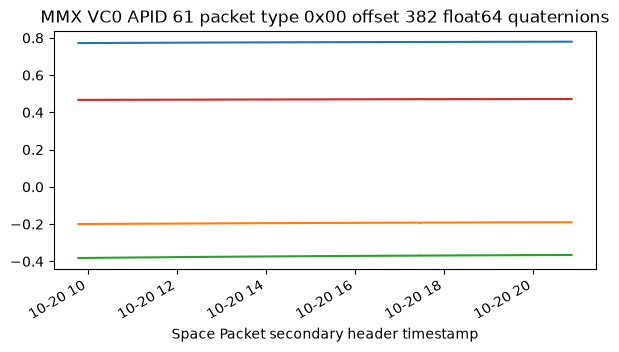

In [63]:
apid61_q2 = vc0_array_by_apid(61, 0)[:, 382:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q2**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q2)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 382 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

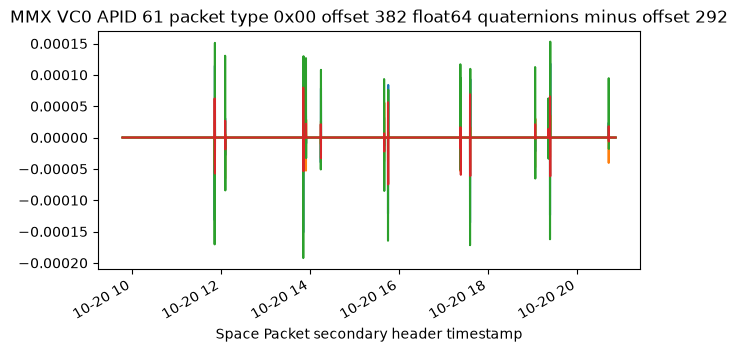

In [64]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q2 - apid61_q0)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 382 float64 quaternions minus offset 292')
plt.xlabel('Space Packet secondary header timestamp');

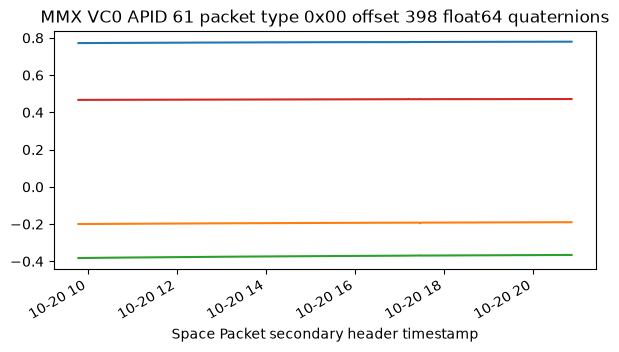

In [65]:
apid61_q3 = vc0_array_by_apid(61, 0)[:, 398:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q3**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q3)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 398 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

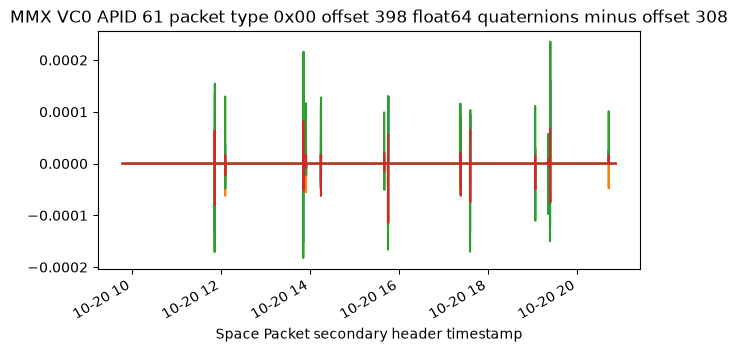

In [66]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q3 - apid61_q1)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 398 float64 quaternions minus offset 308')
plt.xlabel('Space Packet secondary header timestamp');

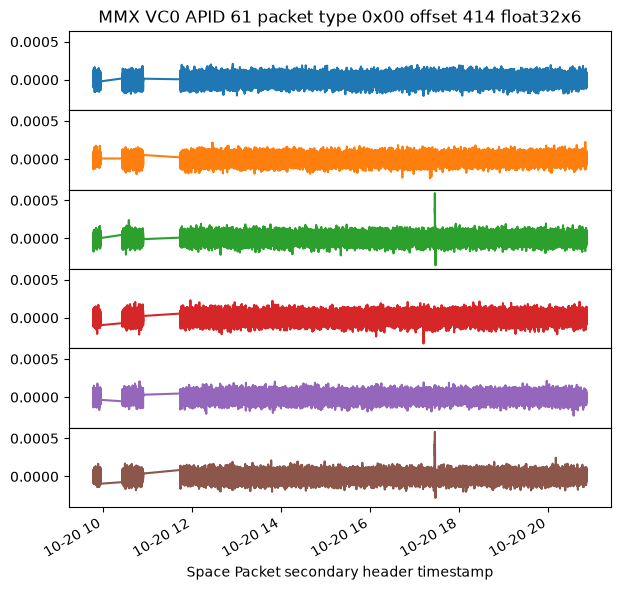

In [67]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 0),
                vc0_array_by_apid(61, 0)[:, 414+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x00 offset 414 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

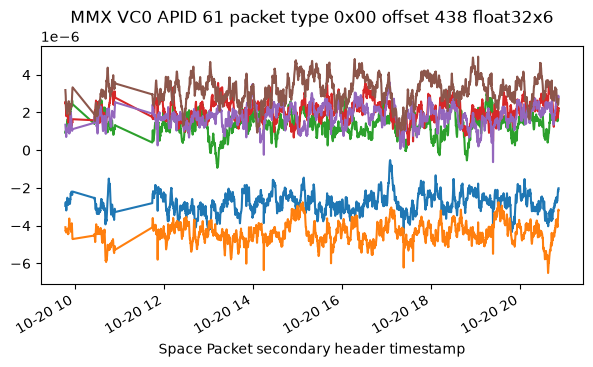

In [68]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0),
         vc0_array_by_apid(61, 0)[:, 438:][:, :6*4].view('float32').byteswap())
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 438 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

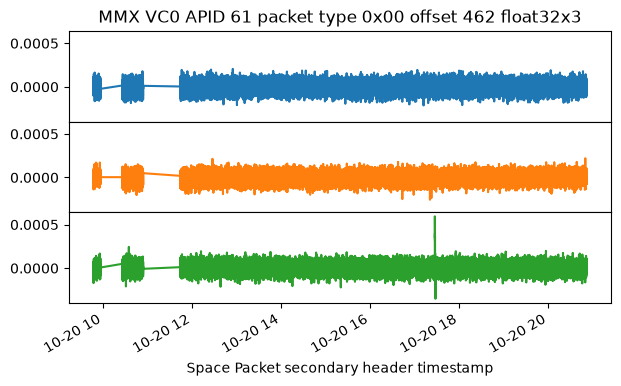

In [69]:
fig, axs = plt.subplots(3, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(3):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 0),
                vc0_array_by_apid(61, 0)[:, 462+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x00 offset 462 float32x3')
plt.xlabel('Space Packet secondary header timestamp');

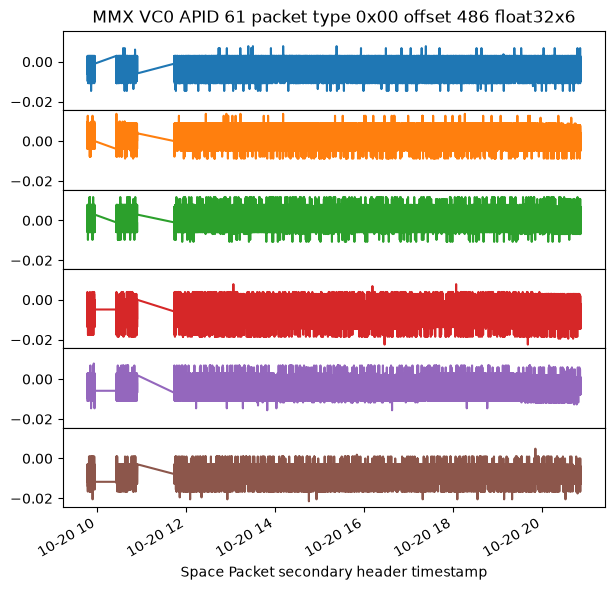

In [70]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 0),
                vc0_array_by_apid(61, 0)[:, 486+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x00 offset 486 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

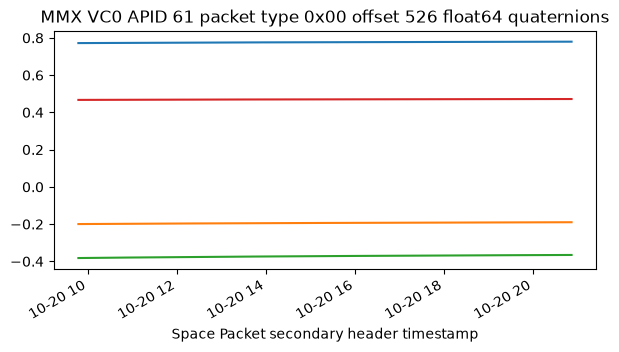

In [71]:
apid61_q4 = vc0_array_by_apid(61, 0)[:, 526:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q4**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q4)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 526 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

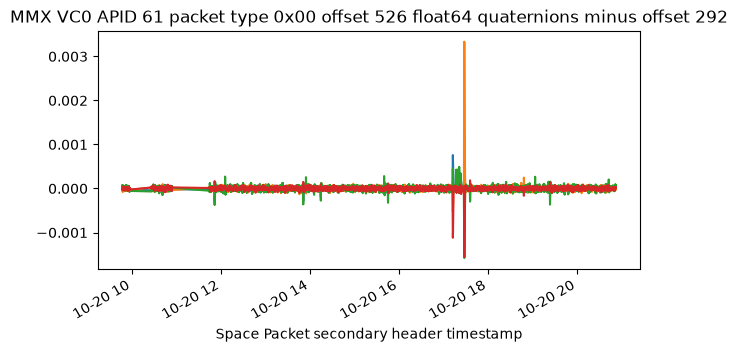

In [72]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q4 - apid61_q0)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 526 float64 quaternions minus offset 292')
plt.xlabel('Space Packet secondary header timestamp');

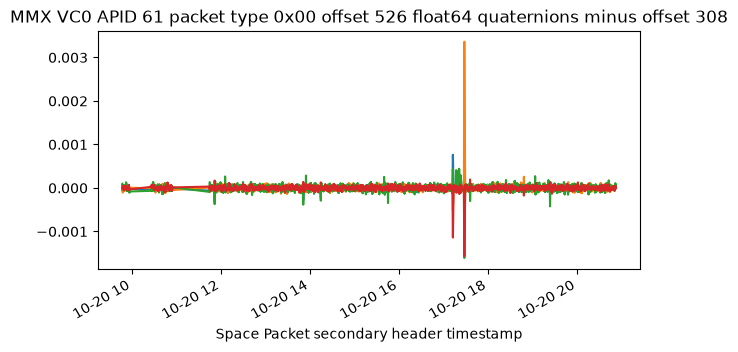

In [73]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q4 - apid61_q1)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 526 float64 quaternions minus offset 308')
plt.xlabel('Space Packet secondary header timestamp');

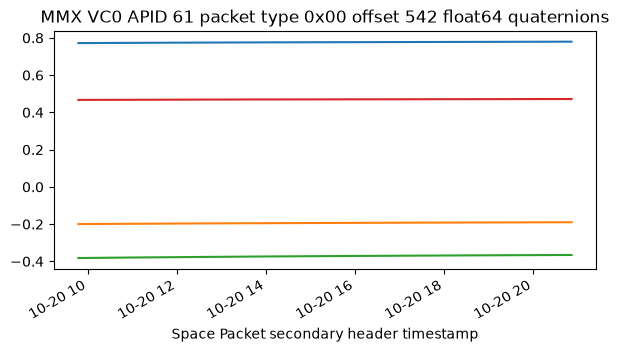

In [74]:
apid61_q5 = vc0_array_by_apid(61, 0)[:, 542:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q5**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q5)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 542 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

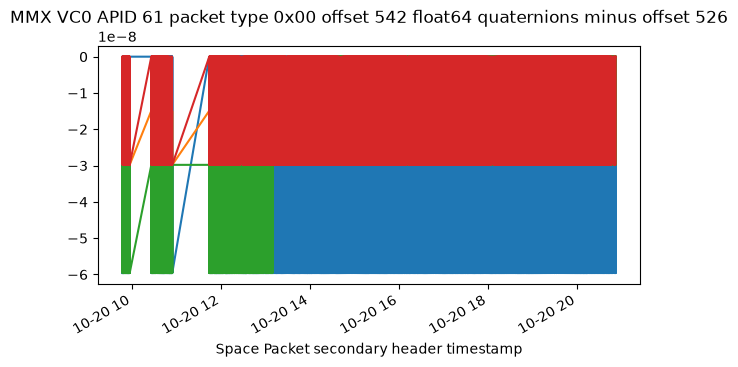

In [75]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q5 - apid61_q4)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 542 float64 quaternions minus offset 526')
plt.xlabel('Space Packet secondary header timestamp');

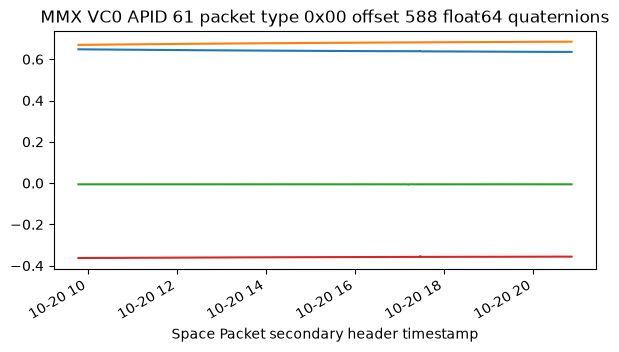

In [76]:
apid61_q6 = vc0_array_by_apid(61, 0)[:, 588:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q6**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q6)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 588 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

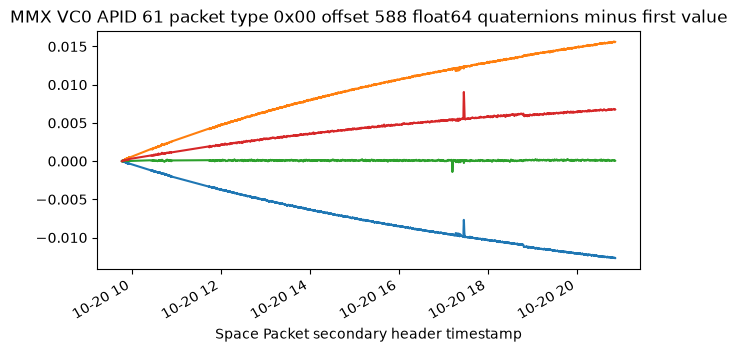

In [77]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q6 - apid61_q6[0])
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 588 float64 quaternions minus first value')
plt.xlabel('Space Packet secondary header timestamp');

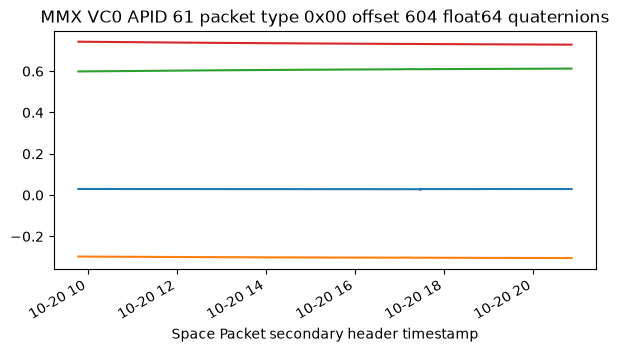

In [78]:
apid61_q7 = vc0_array_by_apid(61, 0)[:, 604:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q7**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q7)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 604 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

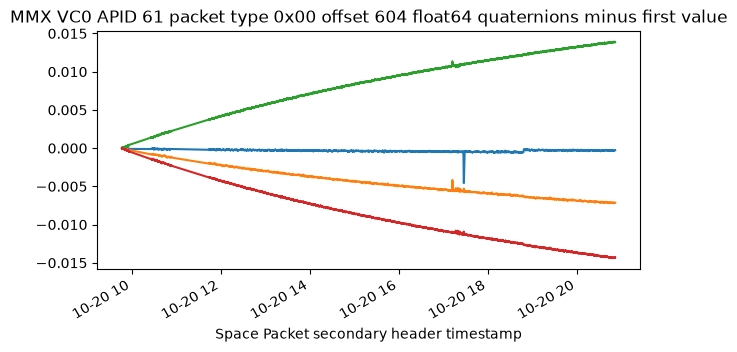

In [79]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q7 - apid61_q7[0])
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 604 float64 quaternions minus first value')
plt.xlabel('Space Packet secondary header timestamp');

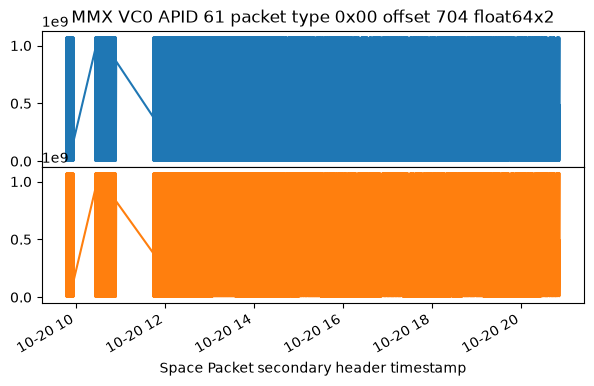

In [80]:
fig, axs = plt.subplots(2, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(2):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 0),
                vc0_array_by_apid(61, 0)[:, 704+8*j:][:, :8].view('float64').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x00 offset 704 float64x2')
plt.xlabel('Space Packet secondary header timestamp');

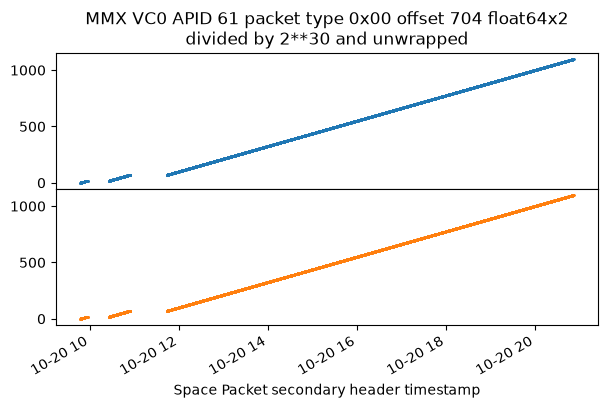

In [81]:
fig, axs = plt.subplots(2, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(2):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 0),
                np.unwrap(vc0_array_by_apid(61, 0)[:, 704+8*j:][:, :8].view('float64').byteswap().ravel() / 2**30 * 2 * np.pi)/(2*np.pi),
                '.', color=f'C{j}', markersize=1)
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x00 offset 704 float64x2\ndivided by 2**30 and unwrapped')
plt.xlabel('Space Packet secondary header timestamp');

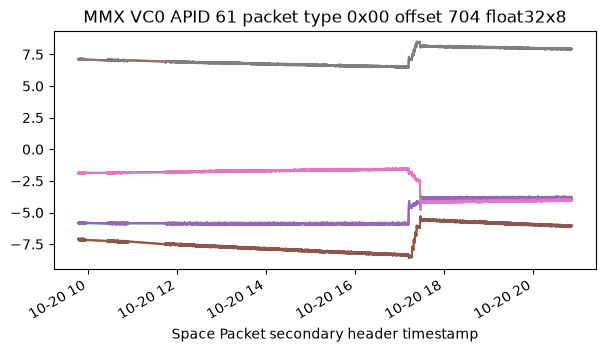

In [82]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0),
         vc0_array_by_apid(61, 0)[:, 772:][:, :8*4].view('float32').byteswap())
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 704 float32x8')
plt.xlabel('Space Packet secondary header timestamp');

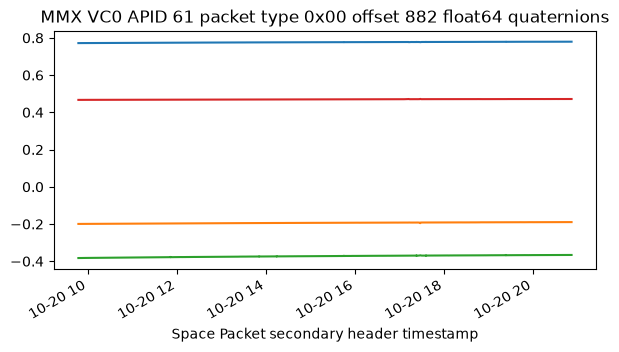

In [83]:
apid61_q8 = vc0_array_by_apid(61, 0)[:, 882:][:, :4*4].view('float32').byteswap()
assert np.all(np.abs(np.sum(apid61_q8**2, axis=1) - 1) < 1e-6)
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q8)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 882 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

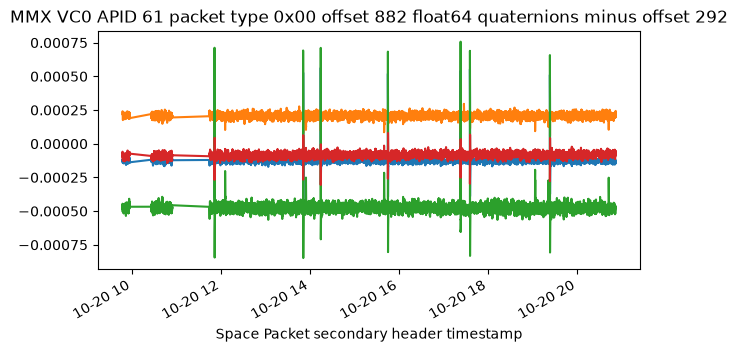

In [84]:
plt.plot(vc0_apid_packet_type_timestamps(61, 0), apid61_q8 - apid61_q0)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x00 offset 882 float64 quaternions minus offset 292')
plt.xlabel('Space Packet secondary header timestamp');

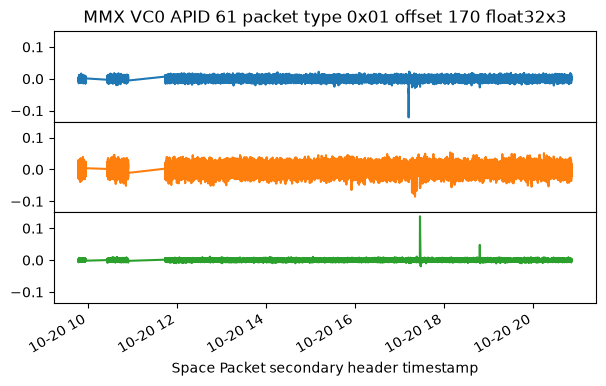

In [85]:
fig, axs = plt.subplots(3, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(3):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 1),
                vc0_array_by_apid(61, 1)[:, 170+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x01 offset 170 float32x3')
plt.xlabel('Space Packet secondary header timestamp');

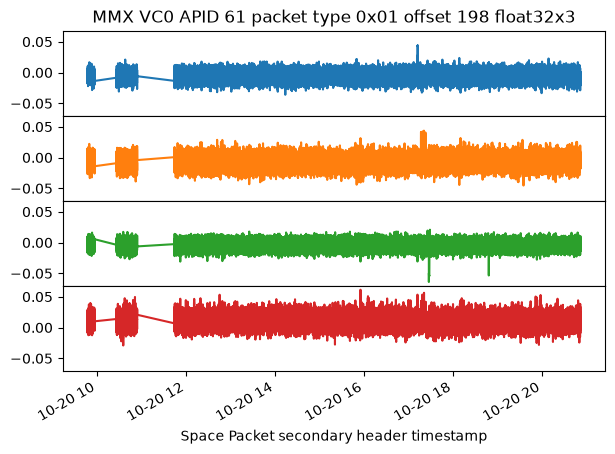

In [86]:
fig, axs = plt.subplots(4, 1, figsize=(7, 5), sharex=True, sharey=True)
for j in range(4):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 1),
                vc0_array_by_apid(61, 1)[:, 198+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x01 offset 198 float32x3')
plt.xlabel('Space Packet secondary header timestamp');

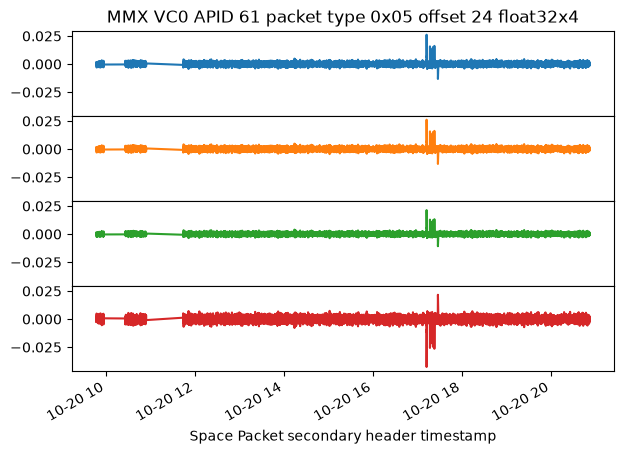

In [87]:
fig, axs = plt.subplots(4, 1, figsize=(7, 5), sharex=True, sharey=True)
for j in range(4):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 5),
                vc0_array_by_apid(61, 5)[:, 24+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x05 offset 24 float32x4')
plt.xlabel('Space Packet secondary header timestamp');

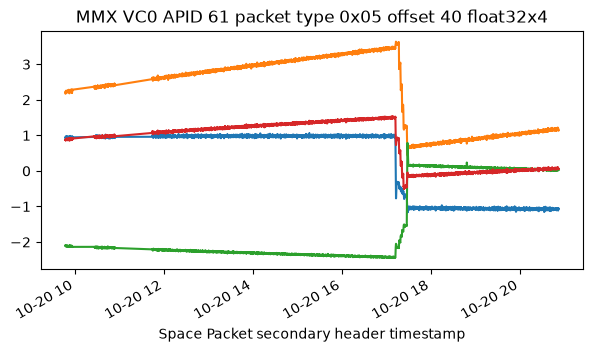

In [88]:
plt.plot(vc0_apid_packet_type_timestamps(61, 5),
         vc0_array_by_apid(61, 5)[:, 40:][:, :4*4].view('float32').byteswap())
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x05 offset 40 float32x4')
plt.xlabel('Space Packet secondary header timestamp');

In [89]:
earth_sun = Horizons(
    id='@399', location='@sun',
    epochs={'start': '2026-10-19T20:30:00', 'stop': '2026-10-20T21:00:00', 'step': '88200'}
).vectors(refplane='earth')
for col in 'xyz':
    earth_sun[col].convert_unit_to('m')
    earth_sun[f'v{col}'].convert_unit_to('m/s')
earth_sun_t = Time(state_vectors_sun['datetime_jd'], format='jd', scale='tdb').utc.datetime64
earth_sun_u = np.array([earth_sun[coord] for coord in 'xyz'])
earth_sun_u /= np.sqrt(np.sum(earth_sun_u**2, axis=0))

earth_sun_interp = np.interp(
    (vc0_apid_packet_type_timestamps(61, 5) - earth_sun_t[0]) / np.timedelta64(1, 's'),
    (earth_sun_t - earth_sun_t[0]) / np.timedelta64(1, 's'),
    np.sqrt(np.sum(np.array([earth_sun[coord] for coord in 'xyz'])**2, axis=0)))

earth_sun_u_interp = np.array([
    np.interp(
        (vc0_apid_packet_type_timestamps(61, 5) - earth_sun_t[0]) / np.timedelta64(1, 's'),
        (earth_sun_t - earth_sun_t[0]) / np.timedelta64(1, 's'),
        earth_sun_u[j])
    for j in range(3)]).T

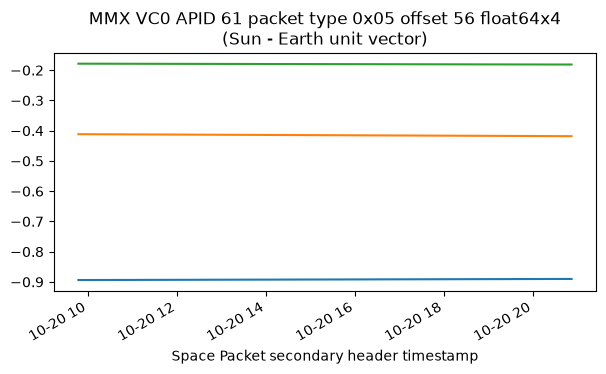

In [90]:
plt.plot(vc0_apid_packet_type_timestamps(61, 5),
        vc0_array_by_apid(61, 5)[:, 56:][:, :8*3].view('float64').byteswap())
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x05 offset 56 float64x4\n(Sun - Earth unit vector)')
plt.xlabel('Space Packet secondary header timestamp');

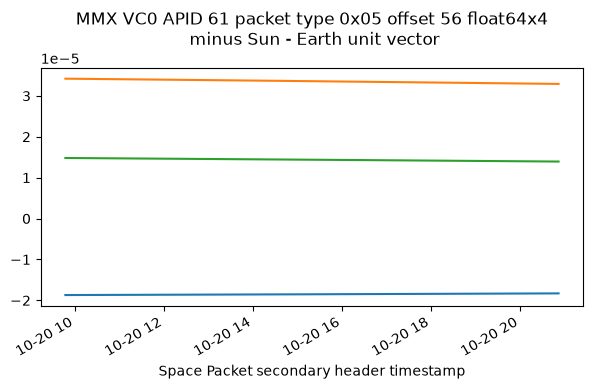

In [91]:
plt.plot(vc0_apid_packet_type_timestamps(61, 5),
        vc0_array_by_apid(61, 5)[:, 56:][:, :8*3].view('float64').byteswap() + earth_sun_u_interp)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x05 offset 56 float64x4\n minus Sun - Earth unit vector')
plt.xlabel('Space Packet secondary header timestamp');

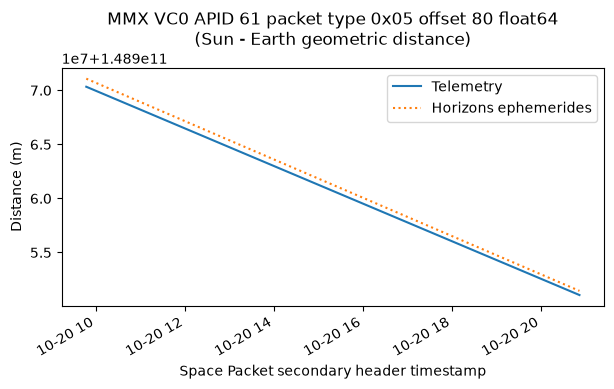

In [92]:
plt.plot(vc0_apid_packet_type_timestamps(61, 5),
         vc0_array_by_apid(61, 5)[:, 80:][:, :8].view('float64').byteswap(), label='Telemetry')
plt.plot(vc0_apid_packet_type_timestamps(61, 5),
         earth_sun_interp, ':', label='Horizons ephemerides')
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x05 offset 80 float64\n(Sun - Earth geometric distance)')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Distance (m)')
plt.legend();

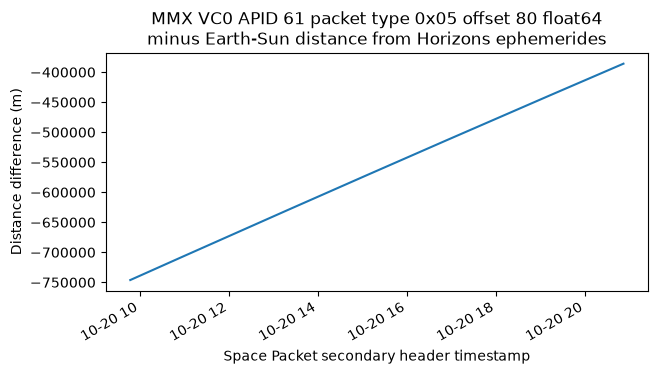

In [93]:
plt.plot(vc0_apid_packet_type_timestamps(61, 5),
         vc0_array_by_apid(61, 5)[:, 80:][:, :8].view('float64').byteswap().ravel() - earth_sun_interp)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x05 offset 80 float64\nminus Earth-Sun distance from Horizons ephemerides')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Distance difference (m)');

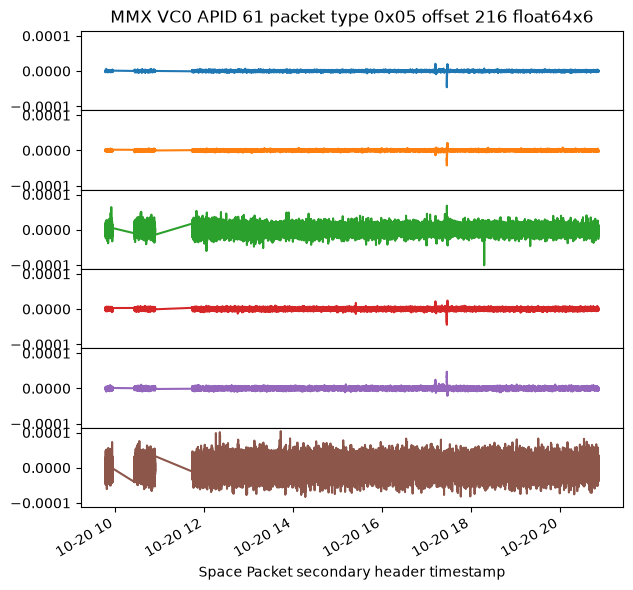

In [94]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc0_apid_packet_type_timestamps(61, 5),
                vc0_array_by_apid(61, 5)[:, 216+8*j:][:, :8].view('float64').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x05 offset 216 float64x6')
plt.xlabel('Space Packet secondary header timestamp');

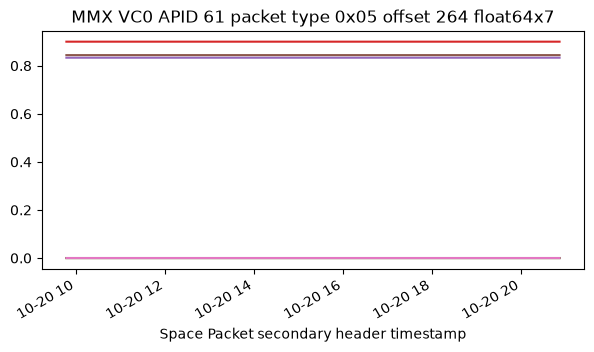

In [95]:
a = vc0_array_by_apid(61, 5)[:, 216+6*8:][:, :7*8].view('float64').byteswap()
plt.plot(vc0_apid_packet_type_timestamps(61, 5), a)
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x05 offset 264 float64x7')
plt.xlabel('Space Packet secondary header timestamp');

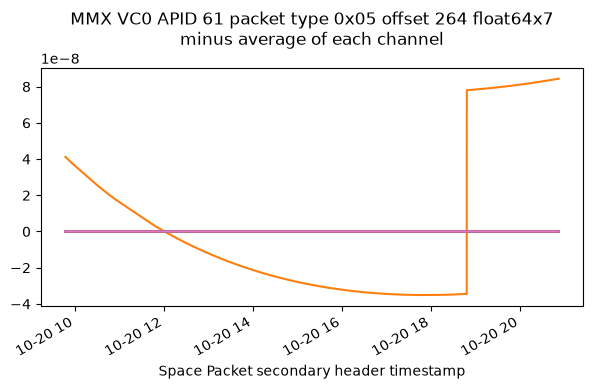

In [96]:
plt.plot(vc0_apid_packet_type_timestamps(61, 5), a - np.average(a, axis=0))
plt.gcf().autofmt_xdate()
plt.title('MMX VC0 APID 61 packet type 0x05 offset 264 float64x7\nminus average of each channel')
plt.xlabel('Space Packet secondary header timestamp');

In [97]:
[p.hex() for p in vc0_payloads_by_apid(817)]

['...']

## VC 1

Virtual channel 1 contains CCSDS Space Packets that have the same format as those in VC0. Similar APIDs are in use. APID 2047 (idle packets) is also in use. Idle packets do not have a secondary header and their payload is all zeros.

In [98]:
vc1_packets = list(ccsds.extract_space_packets(aos, 0xe4, 1))

/home/daniel/contracting/MMX/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 228 VC 1] Broken stream. Last frame count 4607, current frame count 4610
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {frame_count_new}')
/home/daniel/contracting/MMX/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 228 VC 1] Broken stream. Last frame count 4610, current frame count 4613
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {frame_count_new}')
/home/daniel/contracting/MMX/ccsds.py:93: UserWarning: [Space Packet extractor Spacecraft 228 VC 1] Broken stream. Last frame count 4670, current frame count 4672
  warnings.warn(f'[Space Packet extractor Spacecraft {sc_id} VC {virtual_channel}] Broken stream. Last frame count {frame_count}, current frame count {frame_count_new}')
/

In [99]:
vc1_headers = [ccsds.SpacePacketPrimaryHeader.parse(p) for p in vc1_packets]

In [100]:
vc1_headers[:10]

[Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1093, sequence_flags=3, packet_sequence_count_or_name=0, data_length=33),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1081, sequence_flags=3, packet_sequence_count_or_name=17, data_length=18),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=61, sequence_flags=3, packet_sequence_count_or_name=13356, data_length=25),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1081, sequence_flags=3, packet_sequence_count_or_name=18, data_length=18),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1081, sequence_flags=3, packet_sequence_count_or_name=19, data_length=18),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1073, sequence_flags=3, packet_sequence_count_or_name=2, data_length=26),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1073, sequence_flag

In [101]:
[p for p in vc1_headers if p.APID == 2047]

[Container(ccsds_version=0, packet_type=0, secondary_header_flag=False, APID=2047, sequence_flags=3, packet_sequence_count_or_name=0, data_length=627),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=False, APID=2047, sequence_flags=3, packet_sequence_count_or_name=0, data_length=786),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=False, APID=2047, sequence_flags=3, packet_sequence_count_or_name=0, data_length=1020),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=False, APID=2047, sequence_flags=3, packet_sequence_count_or_name=0, data_length=627),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=False, APID=2047, sequence_flags=3, packet_sequence_count_or_name=0, data_length=1046),
 Container(ccsds_version=0, packet_type=0, secondary_header_flag=False, APID=2047, sequence_flags=3, packet_sequence_count_or_name=0, data_length=529)]

In [102]:
assert all(all(b == 0 for b in p[ccsds.SpacePacketPrimaryHeader.sizeof():])
           for (h, p) in zip(vc1_headers, vc1_packets) if h.APID == 2047)

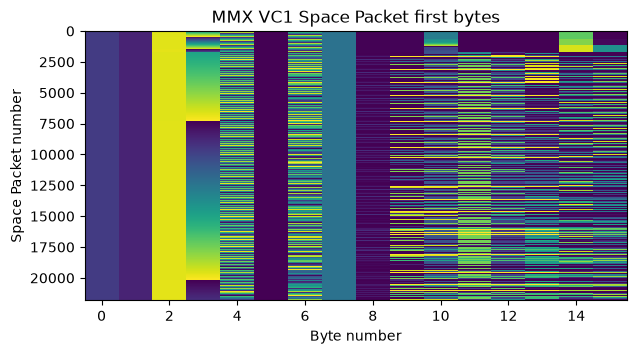

In [103]:
plt.imshow(np.array([np.frombuffer(p[6:6+16], 'uint8') for p in vc1_packets]), aspect='auto', interpolation='none');
plt.title('MMX VC1 Space Packet first bytes')
plt.ylabel('Space Packet number')
plt.xlabel('Byte number');

In [104]:
assert np.all(np.array([p[ccsds.SpacePacketPrimaryHeader.sizeof()]
                        for (h, p) in zip(vc1_headers, vc1_packets) if h.APID != 2047]) == 0b00101100)
assert np.all(np.array([p[ccsds.SpacePacketPrimaryHeader.sizeof()+5]
                        for (h, p) in zip(vc1_headers, vc1_packets) if h.APID != 2047]) == 0)
assert all(p[ccsds.SpacePacketPrimaryHeader.sizeof()+7] in [0x60, 0x69]
           for (h, p) in zip(vc1_headers, vc1_packets) if h.APID != 2047)

In [105]:
collections.Counter([(p[ccsds.SpacePacketPrimaryHeader.sizeof()+7], h.APID)
                     for (h, p) in zip(vc1_headers, vc1_packets) if h.APID != 2047])

Counter({(96, 57): 7772,
         (96, 61): 7704,
         (96, 49): 4768,
         (96, 53): 1552,
         (105, 1073): 10,
         (105, 1081): 7,
         (105, 1089): 3,
         (105, 1097): 2,
         (105, 1098): 2,
         (105, 1093): 1,
         (105, 61): 1,
         (105, 1090): 1})

In [106]:
vc1_apids = collections.Counter([p.APID for p in vc1_headers])
vc1_apids

Counter({57: 7772,
         61: 7705,
         49: 4768,
         53: 1552,
         1073: 10,
         1081: 7,
         2047: 6,
         1089: 3,
         1097: 2,
         1098: 2,
         1093: 1,
         1090: 1})

In [107]:
vc1_secondary_headers = np.array([np.frombuffer(p[ccsds.SpacePacketPrimaryHeader.sizeof():][1:5], 'uint8')
                                  for (h, p) in zip(vc1_headers, vc1_packets) if h.APID != 2047])
vc1_packet_timestamps = ((vc1_secondary_headers.view('uint32').byteswap().ravel() * 1e9) * np.timedelta64(1, 'ns')
                         + np.datetime64('2013-01-01T00:00:00'))
vc1_apid_timestamps = {apid: vc1_packet_timestamps[np.array([h.APID for h in vc1_headers if h.APID != 2047]) == apid]
                       for apid in vc1_apids if apid != 2047}

def vc1_apid_packet_type_timestamps(apid, packet_type):
    return vc1_packet_timestamps[
        np.array([(h.APID, p[ccsds.SpacePacketPrimaryHeader.sizeof()+8]) == (apid, packet_type)
                  for (h, p) in zip(vc1_headers, vc1_packets) if h.APID != 2047])]

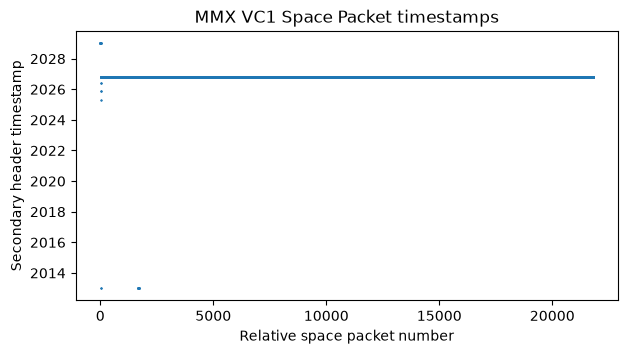

In [108]:
plt.plot(np.arange(len(vc1_packet_timestamps)), vc1_packet_timestamps, '.', markersize=1)
plt.title('MMX VC1 Space Packet timestamps')
plt.ylabel('Secondary header timestamp')
plt.xlabel('Relative space packet number');

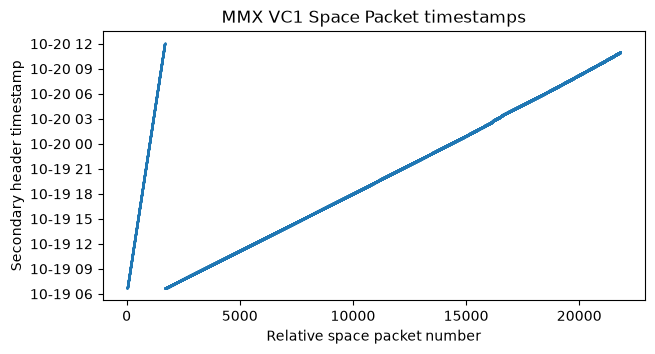

In [109]:
sel = (vc1_packet_timestamps >= np.datetime64('2026-10-01T00:00:00')) & (vc1_packet_timestamps <= np.datetime64('2027-01-01T00:00:00'))
plt.plot(np.arange(len(vc1_packet_timestamps))[sel], vc1_packet_timestamps[sel], '.', markersize=1)
plt.title('MMX VC1 Space Packet timestamps')
plt.ylabel('Secondary header timestamp')
plt.xlabel('Relative space packet number');

In [110]:
vc1_packet_timestamps[~sel]

array(['2029-01-02T14:02:56.000000000', '2029-01-02T16:01:30.000000000',
       '2029-01-02T16:01:30.000000000', '2029-01-02T16:01:30.000000000',
       '2029-01-02T16:01:39.000000000', '2029-01-03T04:49:15.000000000',
       '2029-01-03T04:49:15.000000000', '2029-01-03T04:51:09.000000000',
       '2029-01-03T04:51:37.000000000', '2029-01-03T04:52:02.000000000',
       '2029-01-03T04:53:49.000000000', '2029-01-03T04:56:58.000000000',
       '2029-01-03T04:56:58.000000000', '2029-01-03T05:06:30.000000000',
       '2029-01-03T05:06:30.000000000', '2029-01-03T05:34:08.000000000',
       '2029-01-03T05:34:08.000000000', '2026-06-10T08:33:10.000000000',
       '2013-01-01T00:00:00.000000000', '2026-06-10T08:33:42.000000000',
       '2013-01-01T00:00:00.000000000', '2026-06-10T08:36:53.000000000',
       '2025-11-24T08:29:49.000000000', '2025-11-24T08:30:28.000000000',
       '2025-11-24T08:33:44.000000000', '2025-04-25T19:49:52.000000000',
       '2025-04-25T20:21:43.000000000', '2013-01-01

In [111]:
a = np.where(np.diff(vc1_packet_timestamps[sel]) / np.timedelta64(1, 's') < 0)[0]
assert a.size == 1
a = a[0] + 1
vc1_packet_timestamps[sel][a]

np.datetime64('2026-10-19T06:40:30.000000000')

APID 49: 1654 packets. types = Counter({np.int64(1): 1654})


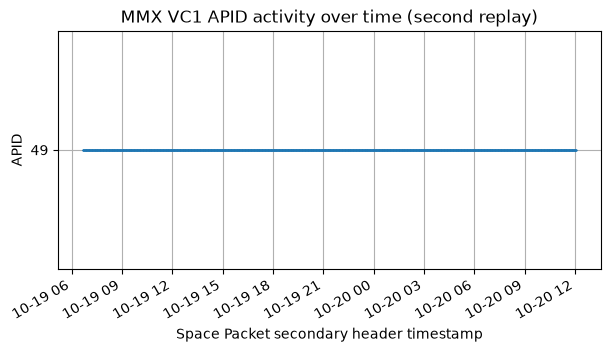

In [112]:
apids_in_use = []
for apid in sorted(vc1_apids):
    apid_sel = np.array([h.APID for h in vc1_headers if h.APID != 2047])[sel][:a] == apid
    ts = vc1_packet_timestamps[sel][:a][apid_sel]
    if len(ts) == 0:
        continue
    k = len(apids_in_use)
    plt.plot(ts, len(ts) * [-k], '.', color=f'C{k}', markersize=1)
    apids_in_use.append(apid)
    types = collections.Counter(
        np.array([p[ccsds.SpacePacketPrimaryHeader.sizeof()+8]
                 for (h, p) in zip(vc1_headers, vc1_packets) if h.APID != 2047])[sel][:a][apid_sel])
    print(f'APID {apid}: {len(ts)} packets. types = {types}')
plt.yticks(-np.arange(len(apids_in_use)), [str(a) for a in apids_in_use])
plt.ylim(-len(apids_in_use), 1)
plt.grid()
plt.ylabel('APID')
plt.xlabel('Space Packet secondary header timestamp')
plt.title('MMX VC1 APID activity over time (second replay)')
plt.gcf().autofmt_xdate();

APID 49: 3111 packets. types = Counter({np.int64(0): 1556, np.int64(2): 1555})
APID 53: 1551 packets. types = Counter({np.int64(0): 1551})
APID 57: 7764 packets. types = Counter({np.int64(32): 1559, np.int64(16): 1557, np.int64(0): 1555, np.int64(17): 1548, np.int64(18): 1545})
APID 61: 7697 packets. types = Counter({np.int64(5): 1546, np.int64(0): 1543, np.int64(4): 1542, np.int64(2): 1537, np.int64(1): 1529})


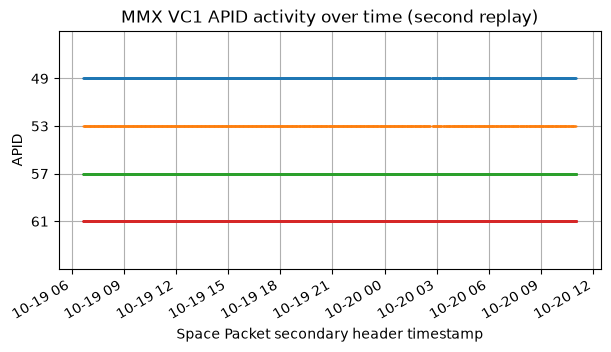

In [113]:
apids_in_use = []
for apid in sorted(vc1_apids):
    apid_sel = np.array([h.APID for h in vc1_headers if h.APID != 2047])[sel][a:] == apid
    ts = vc1_packet_timestamps[sel][a:][apid_sel]    
    if len(ts) == 0:
        continue
    k = len(apids_in_use)
    plt.plot(ts, len(ts) * [-k], '.', color=f'C{k}', markersize=1)
    apids_in_use.append(apid)
    types = collections.Counter(
        np.array([p[ccsds.SpacePacketPrimaryHeader.sizeof()+8]
                 for (h, p) in zip(vc1_headers, vc1_packets) if h.APID != 2047])[sel][a:][apid_sel])
    print(f'APID {apid}: {len(ts)} packets. types = {types}')
plt.yticks(-np.arange(len(apids_in_use)), [str(a) for a in apids_in_use])
plt.ylim(-len(apids_in_use), 1)
plt.grid()
plt.ylabel('APID')
plt.xlabel('Space Packet secondary header timestamp')
plt.title('MMX VC1 APID activity over time (second replay)')
plt.gcf().autofmt_xdate();

In [114]:
[(t, h) for (h, t) in zip([h for h in vc1_headers if h.APID != 2047], vc1_packet_timestamps)
 if t < np.datetime64('2026-10-01T00:00:00') or t > np.datetime64('2027-01-01T00:00:00')]

[(np.datetime64('2029-01-02T14:02:56.000000000'),
  Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1093, sequence_flags=3, packet_sequence_count_or_name=0, data_length=33)),
 (np.datetime64('2029-01-02T16:01:30.000000000'),
  Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1081, sequence_flags=3, packet_sequence_count_or_name=17, data_length=18)),
 (np.datetime64('2029-01-02T16:01:30.000000000'),
  Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=61, sequence_flags=3, packet_sequence_count_or_name=13356, data_length=25)),
 (np.datetime64('2029-01-02T16:01:30.000000000'),
  Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1081, sequence_flags=3, packet_sequence_count_or_name=18, data_length=18)),
 (np.datetime64('2029-01-02T16:01:39.000000000'),
  Container(ccsds_version=0, packet_type=0, secondary_header_flag=True, APID=1081, sequence_flags=3, packet_sequence_count_or_name=19, dat

In [115]:
{apid: collections.Counter([p.data_length for p in vc1_headers if p.APID == apid])
 for apid in vc1_apids if apid != 2047}

{1093: Counter({33: 1}),
 1081: Counter({18: 7}),
 61: Counter({568: 4629, 968: 3075, 25: 1}),
 1073: Counter({26: 4, 15: 4, 30: 2}),
 1089: Counter({30: 3}),
 1097: Counter({33: 2}),
 1090: Counter({30: 1}),
 1098: Counter({33: 2}),
 49: Counter({249: 3113, 441: 1655}),
 57: Counter({249: 1560, 364: 1559, 471: 1556, 292: 1550, 375: 1547}),
 53: Counter({249: 1552})}

In [116]:
{apid: collections.Counter([(p[ccsds.SpacePacketPrimaryHeader.sizeof()+8], h.data_length)
                            for (h, p) in zip(vc1_headers, vc1_packets) if h.APID == apid])
 for apid in vc1_apids if apid != 2047}

{1093: Counter({(240, 33): 1}),
 1081: Counter({(33, 18): 7}),
 61: Counter({(5, 568): 1547,
          (0, 968): 1544,
          (4, 568): 1543,
          (2, 568): 1539,
          (1, 968): 1531,
          (240, 25): 1}),
 1073: Counter({(240, 26): 4, (240, 15): 4, (240, 30): 2}),
 1089: Counter({(240, 30): 3}),
 1097: Counter({(240, 33): 2}),
 1090: Counter({(240, 30): 1}),
 1098: Counter({(240, 33): 2}),
 49: Counter({(1, 441): 1655, (0, 249): 1557, (2, 249): 1556}),
 57: Counter({(32, 249): 1560,
          (16, 364): 1559,
          (0, 471): 1556,
          (17, 292): 1550,
          (18, 375): 1547}),
 53: Counter({(0, 249): 1552})}

In [117]:
def vc1_payloads_by_apid(apid, packet_type=None):
    return [p[ccsds.SpacePacketPrimaryHeader.sizeof() + 8:] for (h, p) in zip(vc1_headers, vc1_packets)
            if h.APID == apid and (packet_type is None or p[ccsds.SpacePacketPrimaryHeader.sizeof()+8] == packet_type)]

def vc1_array_by_apid(apid, packet_type):
    return np.array([np.frombuffer(p, 'uint8') for p in vc1_payloads_by_apid(apid, packet_type)])

def vc1_plot_apid(apid, packet_type, *, vmax=255, byte_sel=None):
    a = vc1_array_by_apid(apid, packet_type)
    if len(a) == 0:
        return
    plt.figure(figsize=(10, 4))
    if byte_sel is not None:
        a = a[:, byte_sel]
    plt.imshow(a, aspect='auto', interpolation='None', vmin=0, vmax=vmax)
    plt.title(f'MMX VC1 APID {apid} packet type 0x{packet_type:02x}')
    plt.ylabel('Packet number')
    plt.xlabel('Payload byte number')

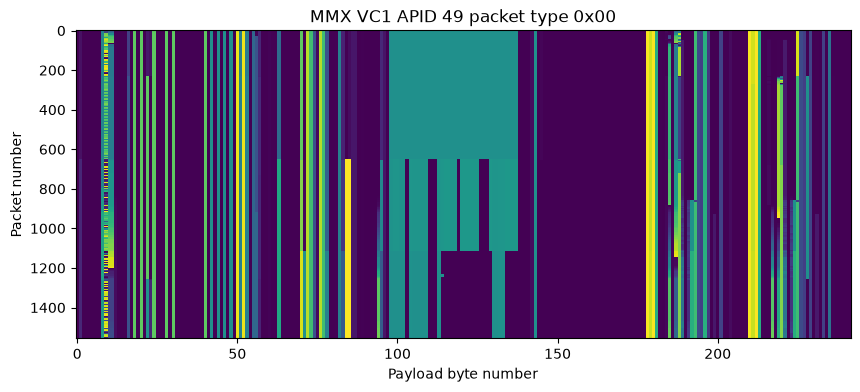

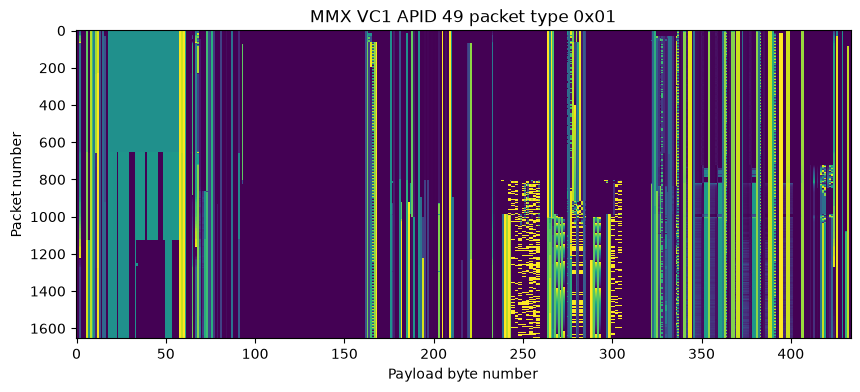

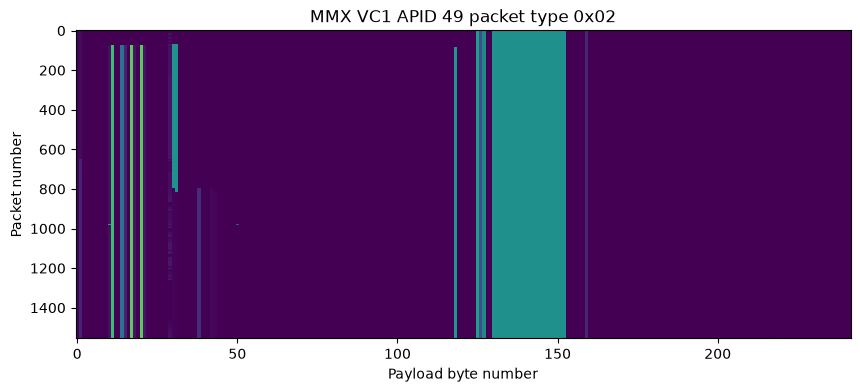

In [118]:
for packet_type in range(3):
    vc1_plot_apid(49, packet_type)

In [119]:
apid49_vc1_f64_timestamps = vc1_array_by_apid(49, 1)[:, 162:][:, :8].view('float64').byteswap().ravel()
apid49_vc1_f64_timestamps = (apid49_vc1_f64_timestamps * 1e9) * np.timedelta64(1, 'ns') + np.datetime64('2000-01-01T12:00:00')

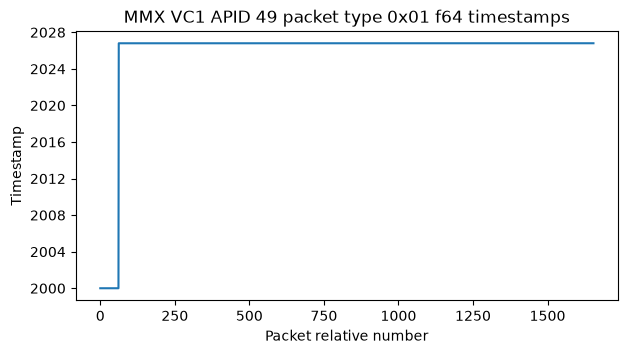

In [120]:
plt.plot(apid49_vc1_f64_timestamps)
plt.xlabel('Packet relative number')
plt.ylabel('Timestamp')
plt.title('MMX VC1 APID 49 packet type 0x01 f64 timestamps');

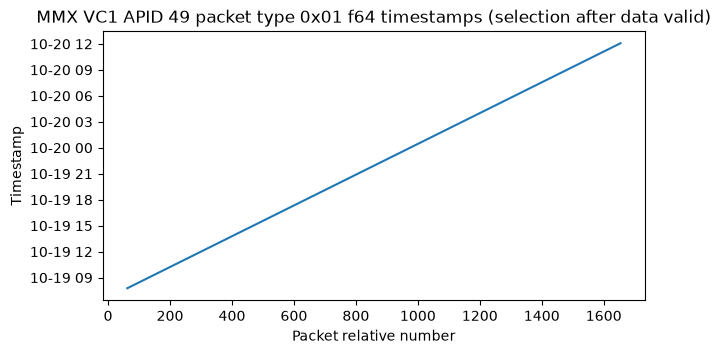

In [121]:
sel = apid49_vc1_f64_timestamps >= np.datetime64('2026-01-01T00:00:00')
plt.plot(np.arange(apid49_vc1_f64_timestamps.size)[sel], apid49_vc1_f64_timestamps[sel])
plt.xlabel('Packet relative number')
plt.ylabel('Timestamp')
plt.title('MMX VC1 APID 49 packet type 0x01 f64 timestamps (selection after data valid)');

In [122]:
timestamp_diff = (apid49_vc1_f64_timestamps - vc1_apid_packet_type_timestamps(49, 1)) / np.timedelta64(1, 's')
assert np.all(timestamp_diff[sel] == timestamp_diff[sel][0])
timestamp_diff[sel][0]

np.float64(34.68746944)

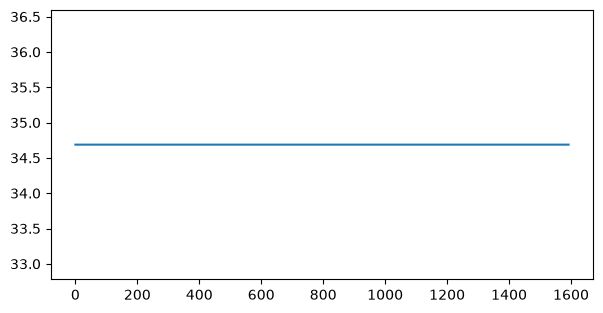

In [123]:
plt.plot(timestamp_diff[sel])

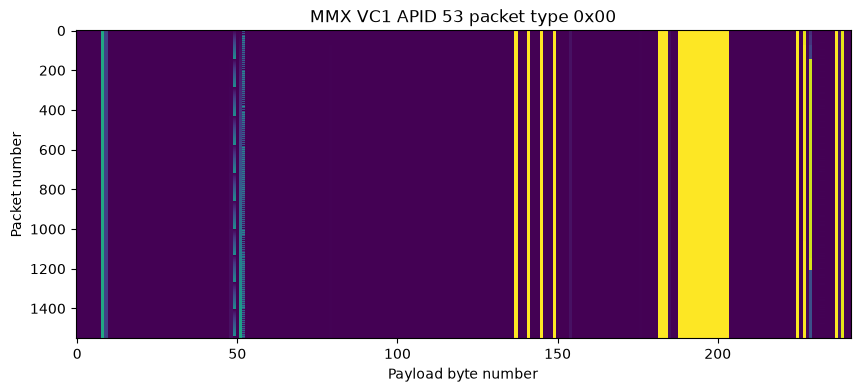

In [124]:
vc1_plot_apid(53, 0)

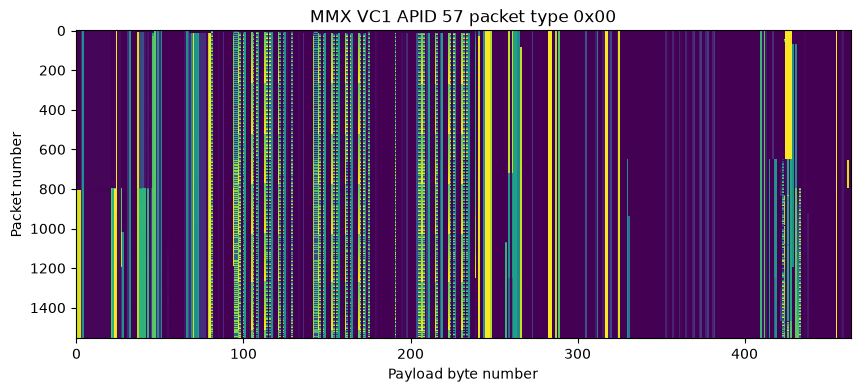

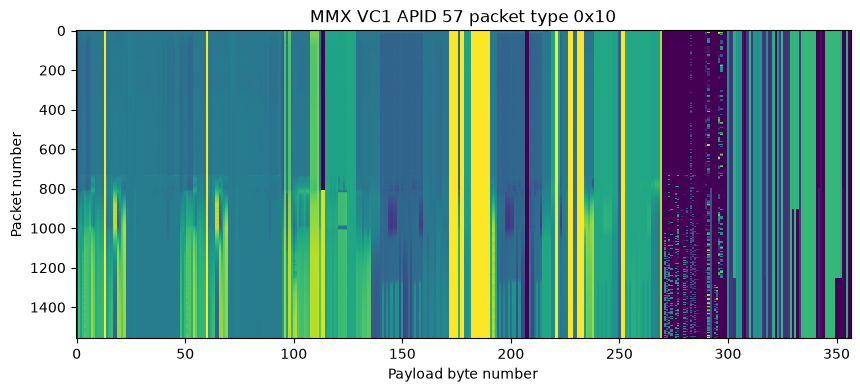

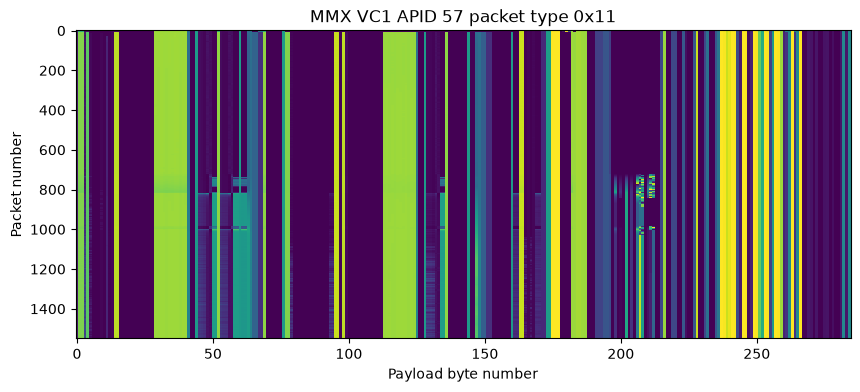

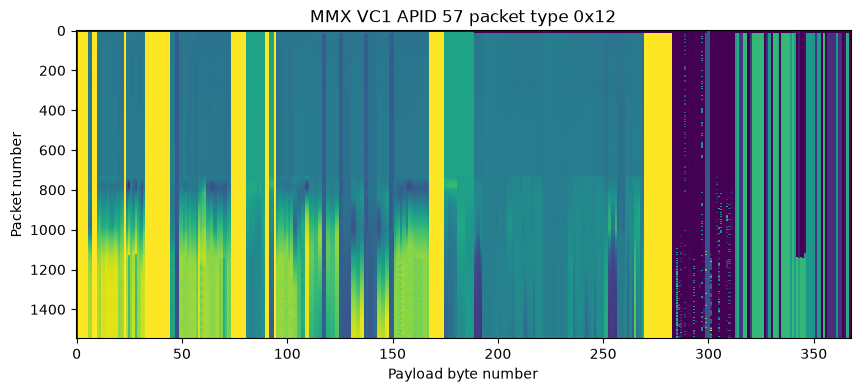

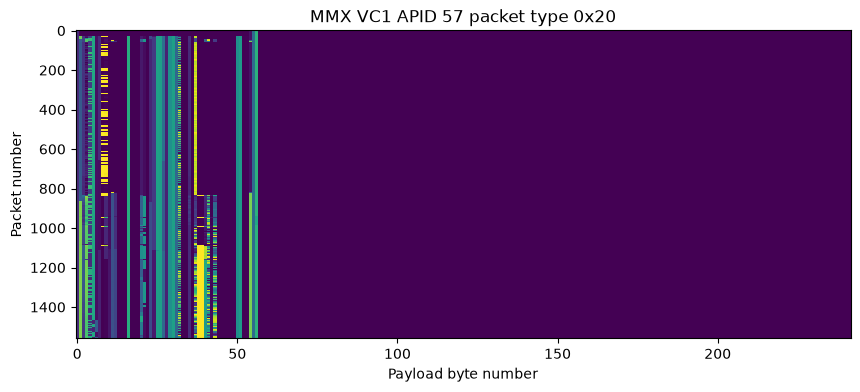

In [125]:
for packet_type in [0, 16, 17, 18, 32]:
    vc1_plot_apid(57, packet_type)

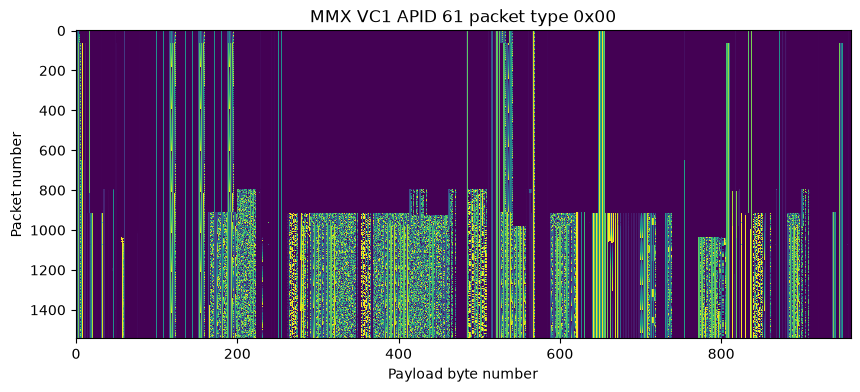

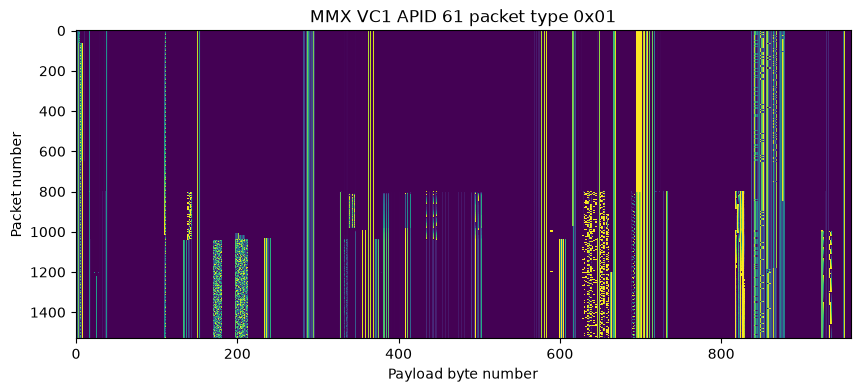

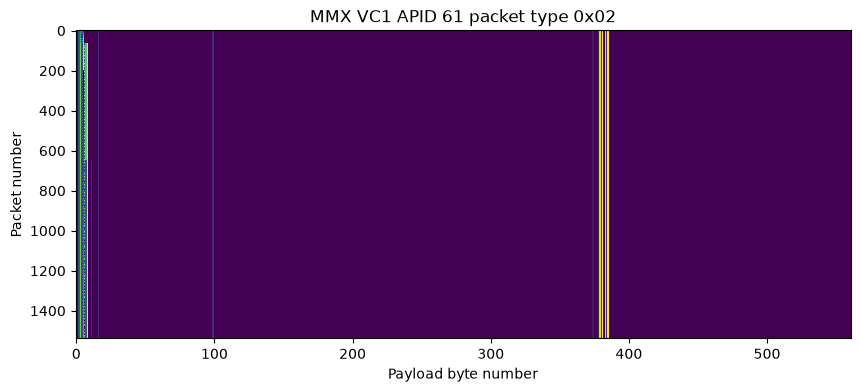

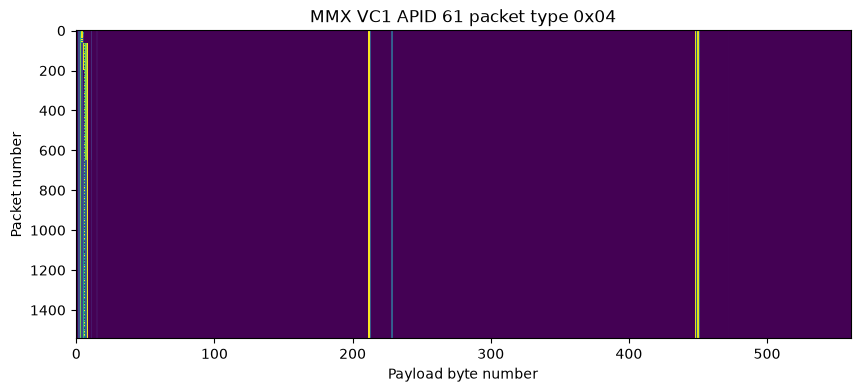

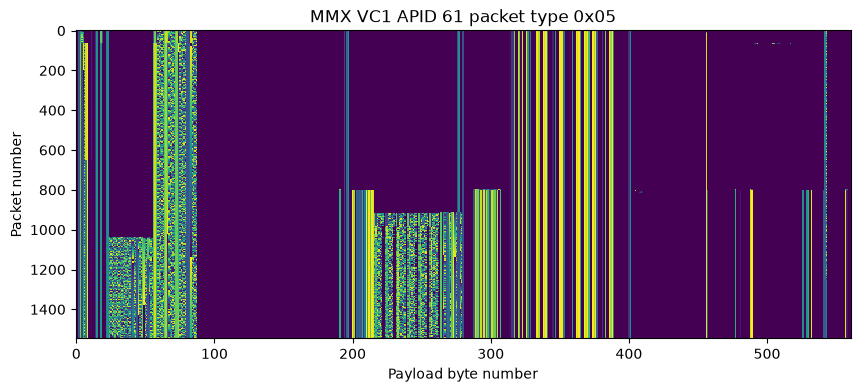

In [126]:
for packet_type in [0, 1, 2, 4, 5]:
    vc1_plot_apid(61, packet_type)

In [127]:
apid61_vc1_f64_timestamps = vc1_array_by_apid(61, 0)[:, 2:][:, :8].view('float64').byteswap().ravel()
apid61_vc1_f64_timestamps = (apid61_vc1_f64_timestamps * 1e9) * np.timedelta64(1, 'ns') + np.datetime64('2000-01-01T12:00:00')
apid61_vc1_f64_timestamps[:3]

array(['2000-01-01T12:00:33.062500000', '2000-01-01T12:01:37.062500000',
       '2000-01-01T12:02:41.062500000'], dtype='datetime64[ns]')

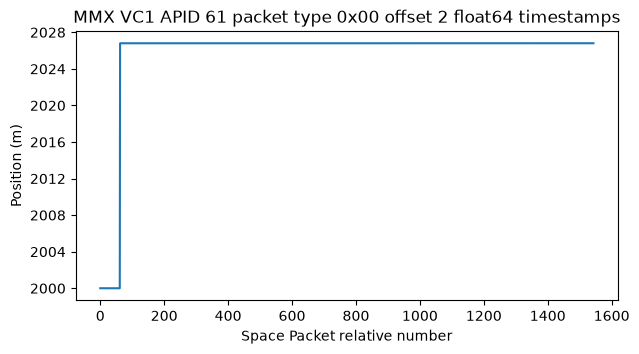

In [128]:
plt.plot(apid61_vc1_f64_timestamps)
plt.title('MMX VC1 APID 61 packet type 0x00 offset 2 float64 timestamps')
plt.xlabel('Space Packet relative number')
plt.ylabel('Position (m)');

In [129]:
vc1_apid61_0_sel = vc1_apid_packet_type_timestamps(61, 0) >= np.datetime64('2026-01-01T00:00')

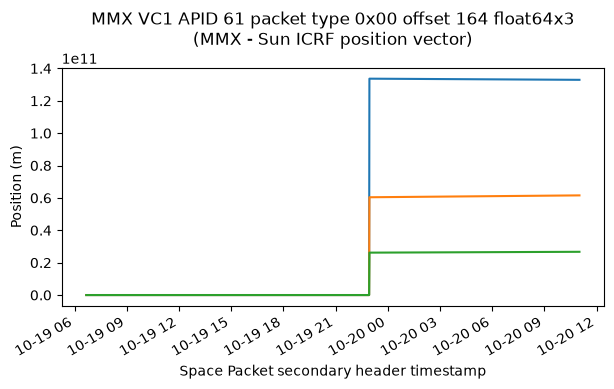

In [130]:
apid61_sun_r = vc1_array_by_apid(61, 0)[:, 164:][:, :3*8].view('float64').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_sun_r[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 164 float64x3\n(MMX - Sun ICRF position vector)')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Position (m)');

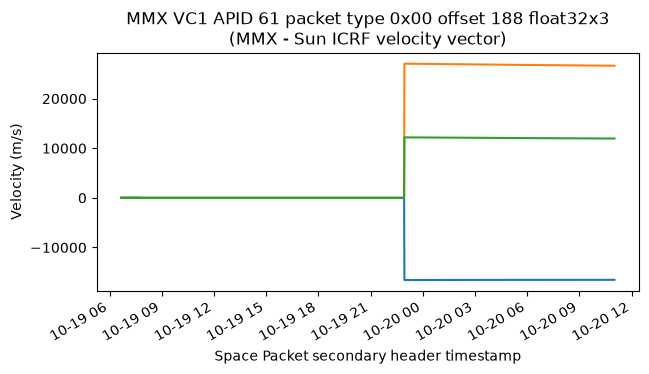

In [131]:
apid61_sun_v = vc1_array_by_apid(61, 0)[:, 188:][:, :4*3].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_sun_v[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 188 float32x3\n(MMX - Sun ICRF velocity vector)')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Velocity (m/s)');

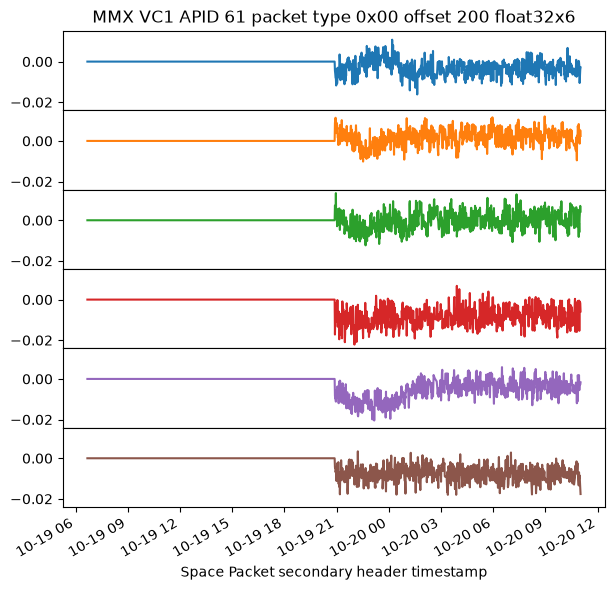

In [132]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
                vc1_array_by_apid(61, 0)[:, 200+4*j:][:, :4].view('float32').byteswap()[vc1_apid61_0_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x00 offset 200 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

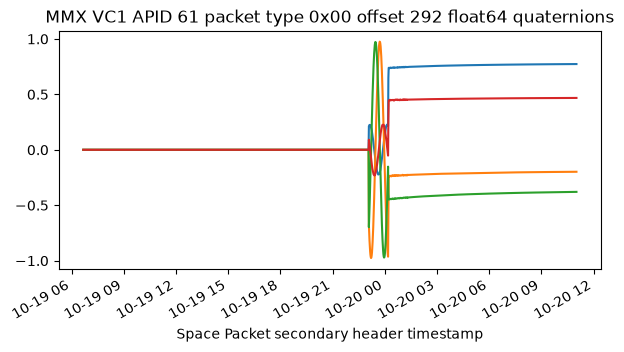

In [133]:
apid61_vc1_q0 = vc1_array_by_apid(61, 0)[:, 292:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q0[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

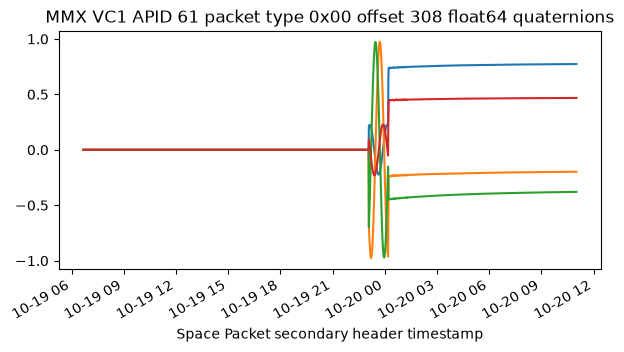

In [134]:
apid61_vc1_q1 = vc1_array_by_apid(61, 0)[:, 308:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q1[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 308 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

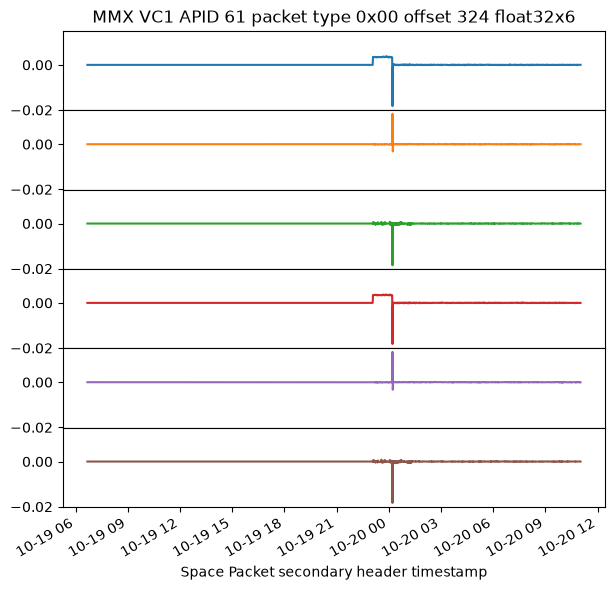

In [135]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
                vc1_array_by_apid(61, 0)[:, 324+4*j:][:, :4].view('float32').byteswap()[vc1_apid61_0_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x00 offset 324 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

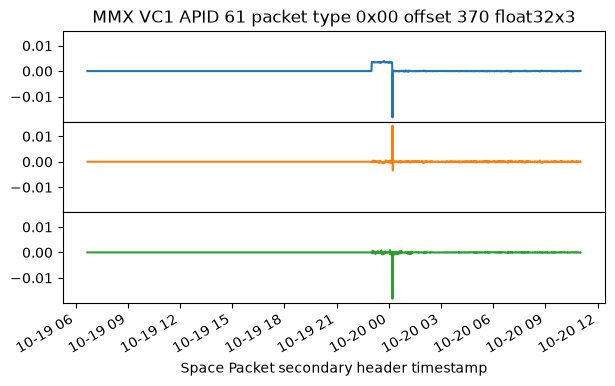

In [136]:
fig, axs = plt.subplots(3, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(3):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
                vc1_array_by_apid(61, 0)[:, 370+4*j:][:, :4].view('float32').byteswap()[vc1_apid61_0_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x00 offset 370 float32x3')
plt.xlabel('Space Packet secondary header timestamp');

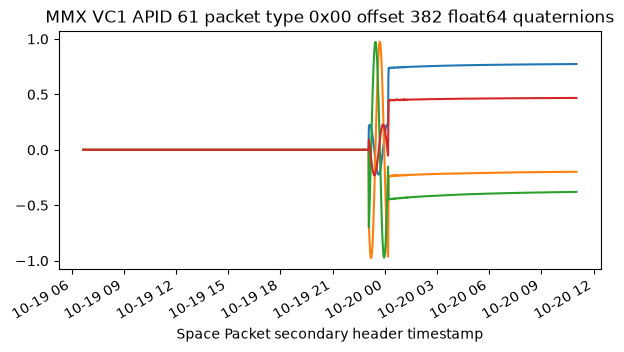

In [137]:
apid61_vc1_q2 = vc1_array_by_apid(61, 0)[:, 382:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q2[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 382 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

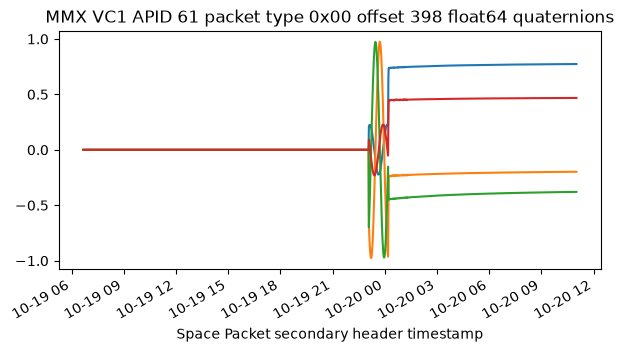

In [138]:
apid61_vc1_q2 = vc1_array_by_apid(61, 0)[:, 398:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q2[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 398 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

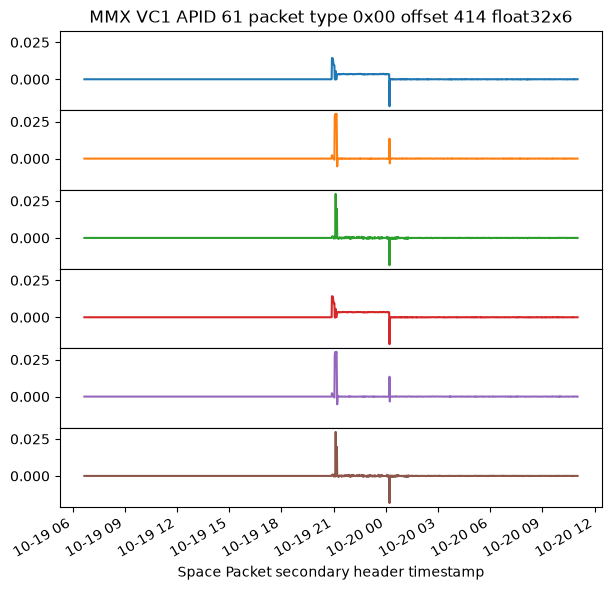

In [139]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
                vc1_array_by_apid(61, 0)[:, 414+4*j:][:, :4].view('float32').byteswap()[vc1_apid61_0_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x00 offset 414 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

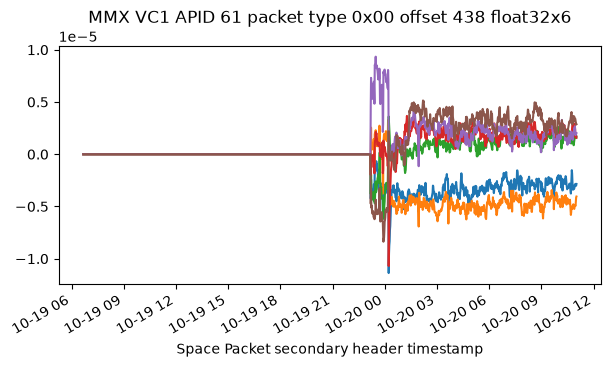

In [140]:
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
         vc1_array_by_apid(61, 0)[:, 438:][:, :6*4].view('float32').byteswap()[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 438 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

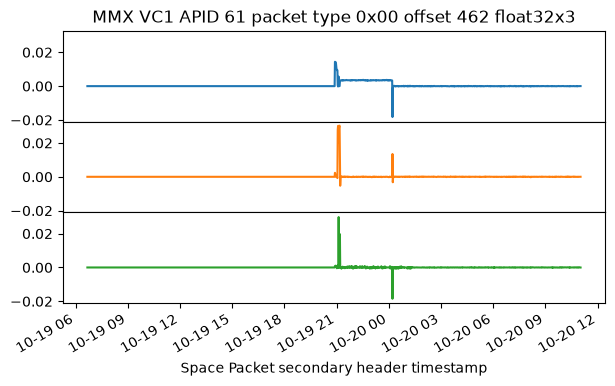

In [141]:
fig, axs = plt.subplots(3, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(3):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
                vc1_array_by_apid(61, 0)[:, 462+4*j:][:, :4].view('float32').byteswap()[vc1_apid61_0_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x00 offset 462 float32x3')
plt.xlabel('Space Packet secondary header timestamp');

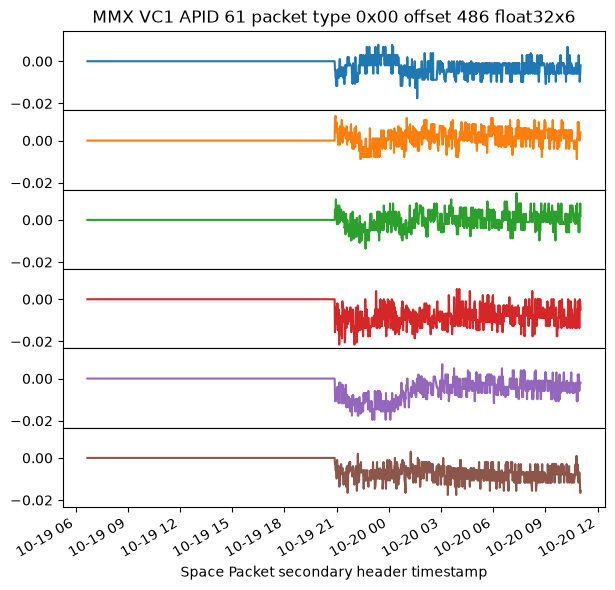

In [142]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
                vc1_array_by_apid(61, 0)[:, 486+4*j:][:, :4].view('float32').byteswap()[vc1_apid61_0_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x00 offset 486 float32x6')
plt.xlabel('Space Packet secondary header timestamp');

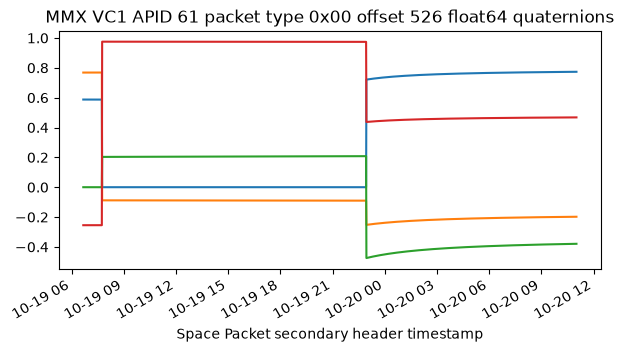

In [143]:
apid61_vc1_q4 = vc1_array_by_apid(61, 0)[:, 526:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q4[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 526 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

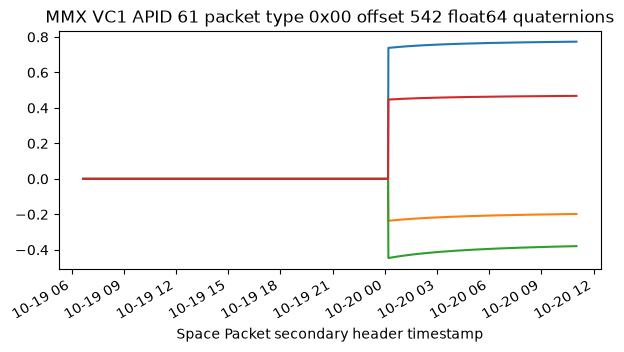

In [144]:
apid61_vc1_q5 = vc1_array_by_apid(61, 0)[:, 542:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q5[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 542 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

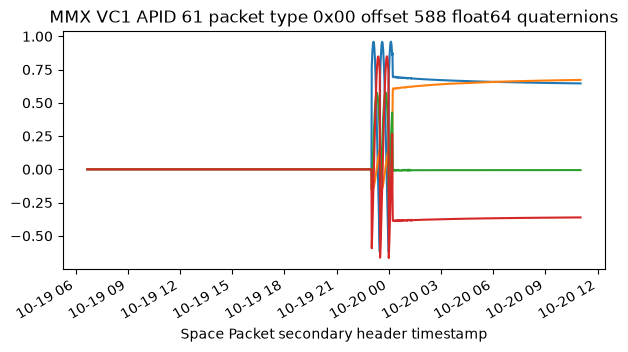

In [145]:
apid61_vc1_q6 = vc1_array_by_apid(61, 0)[:, 588:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q6[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 588 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

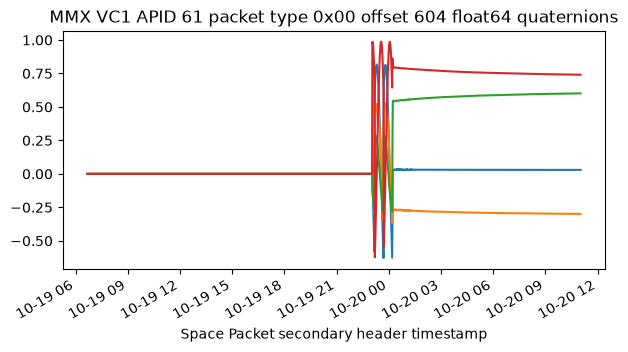

In [146]:
apid61_vc1_q7 = vc1_array_by_apid(61, 0)[:, 604:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q7[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 604 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

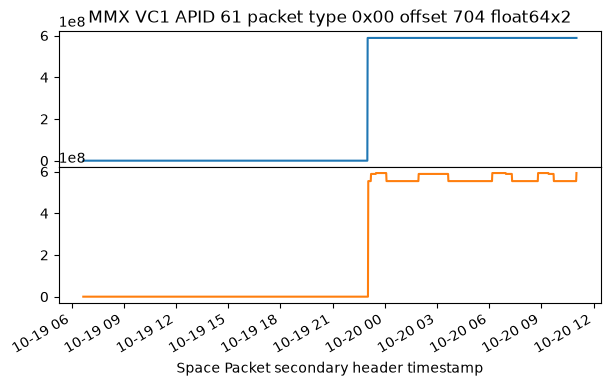

In [147]:
fig, axs = plt.subplots(2, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(2):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
                vc1_array_by_apid(61, 0)[:, 704+8*j:][:, :8].view('float64').byteswap()[vc1_apid61_0_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x00 offset 704 float64x2')
plt.xlabel('Space Packet secondary header timestamp');

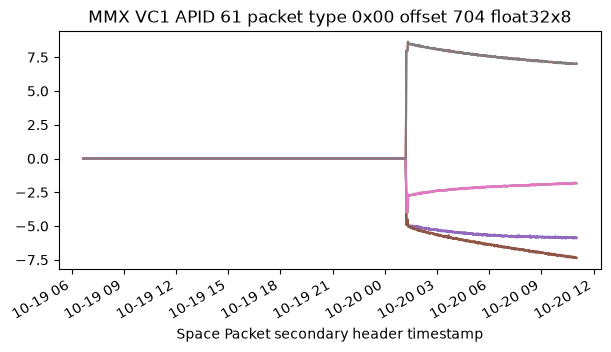

In [148]:
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel],
         vc1_array_by_apid(61, 0)[:, 772:][:, :8*4].view('float32').byteswap()[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 704 float32x8')
plt.xlabel('Space Packet secondary header timestamp');

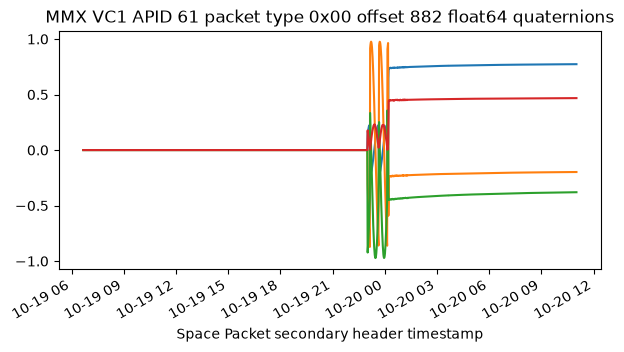

In [149]:
apid61_vc1_q8 = vc1_array_by_apid(61, 0)[:, 882:][:, :4*4].view('float32').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 0)[vc1_apid61_0_sel], apid61_vc1_q8[vc1_apid61_0_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 882 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

In [150]:
vc1_apid61_1_sel = vc1_apid_packet_type_timestamps(61, 1) >= np.datetime64('2026-01-01T00:00')

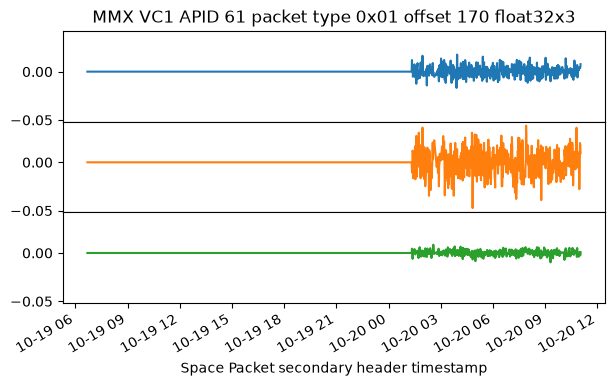

In [151]:
fig, axs = plt.subplots(3, 1, figsize=(7, 4), sharex=True, sharey=True)
for j in range(3):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 1)[vc1_apid61_1_sel],
                vc1_array_by_apid(61, 1)[:, 170+4*j:][:, :4].view('float32').byteswap()[vc1_apid61_1_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x01 offset 170 float32x3')
plt.xlabel('Space Packet secondary header timestamp');

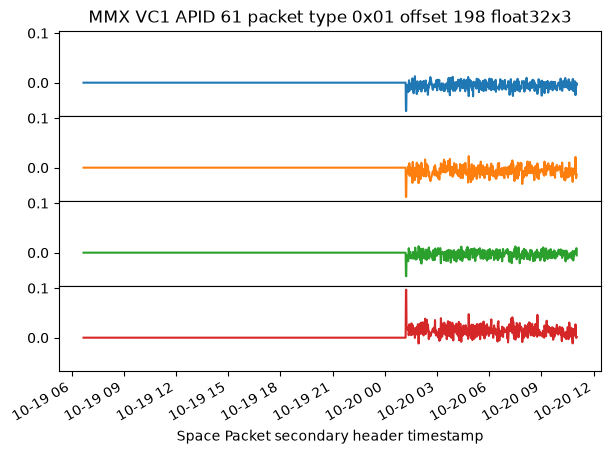

In [152]:
fig, axs = plt.subplots(4, 1, figsize=(7, 5), sharex=True, sharey=True)
for j in range(4):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 1)[vc1_apid61_1_sel],
                vc1_array_by_apid(61, 1)[vc1_apid61_1_sel, 198+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x01 offset 198 float32x3')
plt.xlabel('Space Packet secondary header timestamp');

In [153]:
vc1_apid61_5_sel = vc1_apid_packet_type_timestamps(61, 5) >= np.datetime64('2026-01-01T00:00')

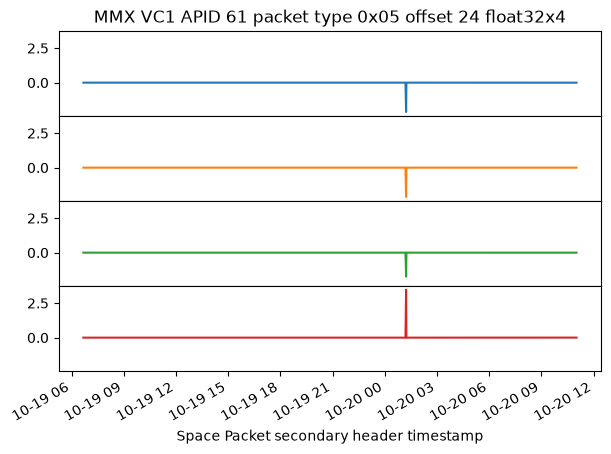

In [154]:
fig, axs = plt.subplots(4, 1, figsize=(7, 5), sharex=True, sharey=True)
for j in range(4):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 5)[vc1_apid61_5_sel],
                vc1_array_by_apid(61, 5)[vc1_apid61_5_sel, 24+4*j:][:, :4].view('float32').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x05 offset 24 float32x4')
plt.xlabel('Space Packet secondary header timestamp');

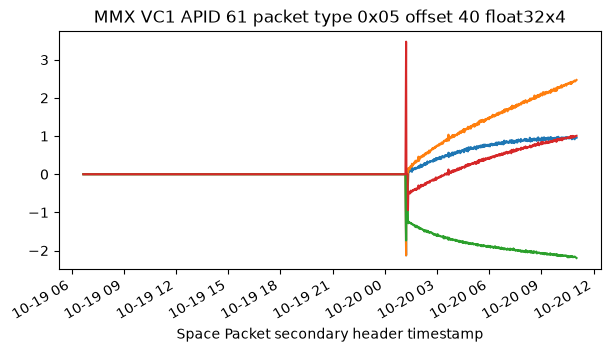

In [155]:
plt.plot(vc1_apid_packet_type_timestamps(61, 5)[vc1_apid61_5_sel],
         vc1_array_by_apid(61, 5)[vc1_apid61_5_sel, 40:][:, :4*4].view('float32').byteswap())
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x05 offset 40 float32x4')
plt.xlabel('Space Packet secondary header timestamp');

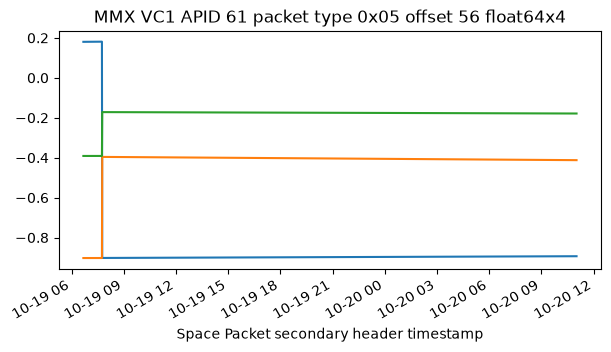

In [156]:
plt.plot(vc1_apid_packet_type_timestamps(61, 5)[vc1_apid61_5_sel],
         vc1_array_by_apid(61, 5)[vc1_apid61_5_sel, 56:][:, :8*3].view('float64').byteswap())
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x05 offset 56 float64x4')
plt.xlabel('Space Packet secondary header timestamp');

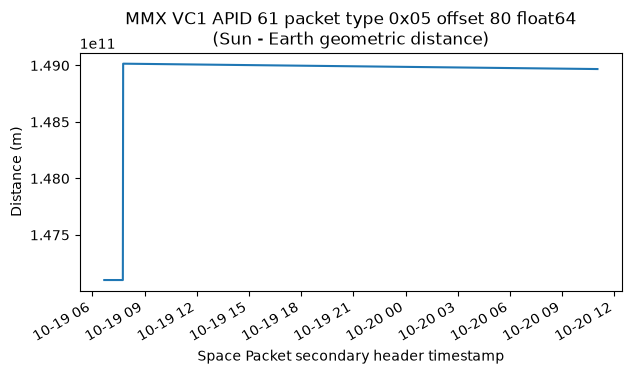

In [157]:
plt.plot(vc1_apid_packet_type_timestamps(61, 5)[vc1_apid61_5_sel],
         vc1_array_by_apid(61, 5)[vc1_apid61_5_sel, 80:][:, :8].view('float64').byteswap(), label='Telemetry')
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x05 offset 80 float64\n(Sun - Earth geometric distance)')
plt.xlabel('Space Packet secondary header timestamp')
plt.ylabel('Distance (m)');

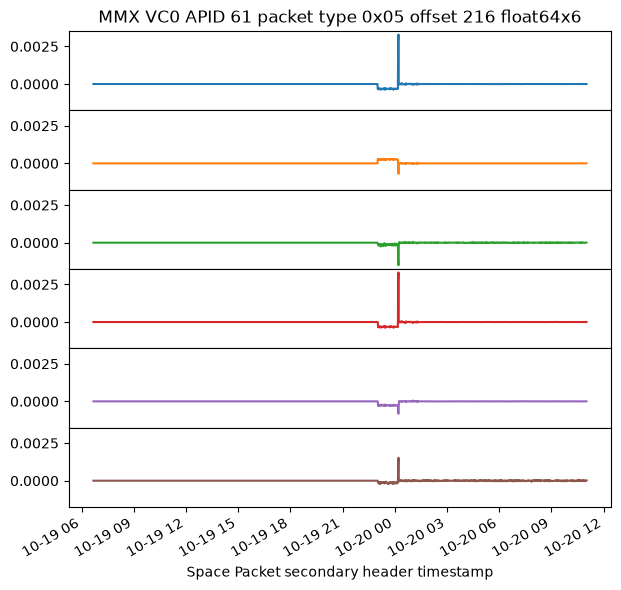

In [158]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(vc1_apid_packet_type_timestamps(61, 5)[vc1_apid61_5_sel],
                vc1_array_by_apid(61, 5)[vc1_apid61_5_sel, 216+8*j:][:, :8].view('float64').byteswap(), color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC0 APID 61 packet type 0x05 offset 216 float64x6')
plt.xlabel('Space Packet secondary header timestamp');

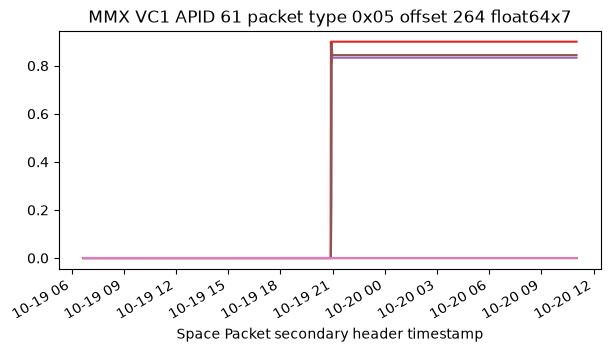

In [159]:
a = vc1_array_by_apid(61, 5)[vc1_apid61_5_sel, 216+6*8:][:, :7*8].view('float64').byteswap()
plt.plot(vc1_apid_packet_type_timestamps(61, 5)[vc1_apid61_5_sel], a)
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x05 offset 264 float64x7')
plt.xlabel('Space Packet secondary header timestamp');

In [160]:
[p.hex() for p in vc1_payloads_by_apid(1073)]

['f0031e1b64cb82000000019cc5002308730000',
 'f0041e1b64cb8201',
 'f0031e1b669b020000000173b5002363f10000',
 'f0041e1b669b0201',
 'f0031e1b68d6b200000001fa73002354200000',
 'f0041e1b68d6b201',
 'f0031e1b6f509200000001e25000231c200000',
 'f0041e1b6f509201',
 'f0011946fa46d70000000000001a1a0000000000000000',
 'f0011841f07dd70000000000001a000000000000000000']

In [161]:
[p.hex() for p in vc1_payloads_by_apid(1081)]

['21021e1ab0da0500000000',
 '21111e1ab0da0d00000000',
 '21141e1ab0e30400000000',
 '210c1e1b653d0e00000000',
 '210d1e1b65590e00000000',
 '210e1e1b65720e00000000',
 '210f1e1b65dd0e00000000']

In [162]:
[p.hex() for p in vc1_payloads_by_apid(1089)]

['f000000000009800190000000000000000000000000000',
 'f0001729c060f7000000000000000000001a0000000000',
 'f0011729c7d7f700000000000000000000000000120000']

In [163]:
[p.hex() for p in vc1_payloads_by_apid(1090)]

['f000000000009800190000000000000000000000000000']

In [164]:
[p.hex() for p in vc1_payloads_by_apid(1093)]

['f0101e1a95100f00000000000b00000000000000000000000000']

In [165]:
[p.hex() for p in vc1_payloads_by_apid(1097)]

['f0011946fa660f004d0007000700000000000000000000000000',
 'f0011841f0a40f004d0008000800000000000000000000000000']

In [166]:
[p.hex() for p in vc1_payloads_by_apid(1098)]

['f0011946fb250f004e0008000800000000000000000000000000',
 'f0011841f1680f004e0008000800000000000000000000000000']

### Attitude quaternions

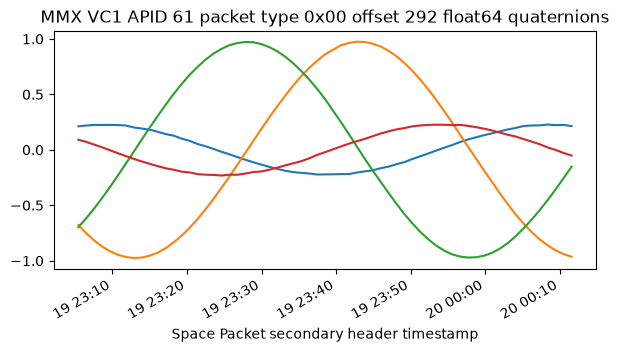

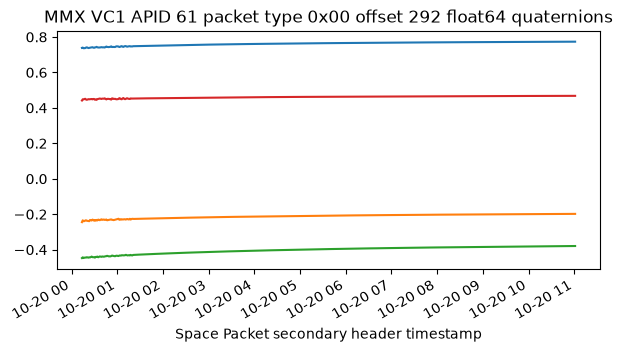

In [167]:
quat_sel = ((vc1_apid_packet_type_timestamps(61, 0) >= np.datetime64('2026-10-19T23:05'))
            & (vc1_apid_packet_type_timestamps(61, 0) <= np.datetime64('2026-10-20T00:12')))
quat_sel2 = vc1_apid_packet_type_timestamps(61, 0) >= np.datetime64('2026-10-20T00:13')
t_quat_sel = vc1_apid_packet_type_timestamps(61, 0)[quat_sel]
t_quat_sel2 = vc1_apid_packet_type_timestamps(61, 0)[quat_sel2]
plt.plot(t_quat_sel, apid61_vc1_q0[quat_sel])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');
plt.figure()
plt.plot(t_quat_sel2, apid61_vc1_q0[quat_sel2])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

In [168]:
q0 = Rotation.from_quat(apid61_vc1_q0[quat_sel])
q0_2 = Rotation.from_quat(apid61_vc1_q0[quat_sel2])

In [169]:
dq0 = q0.inv() * q0[0]
u0 = dq0.as_rotvec() / dq0.magnitude()[:, np.newaxis]
theta0 = dq0.magnitude()
theta0[u0[:, 0] > 0] = 2 * np.pi - theta0[u0[:, 0] > 0]
theta0 = np.unwrap(theta0)
u0[u0[:, 0] > 0] *= -1
u0[u0[:, 0] > 0] *= -1

/tmp/ipykernel_48471/3102767085.py:2: RuntimeWarning: invalid value encountered in divide
  u0 = dq0.as_rotvec() / dq0.magnitude()[:, np.newaxis]


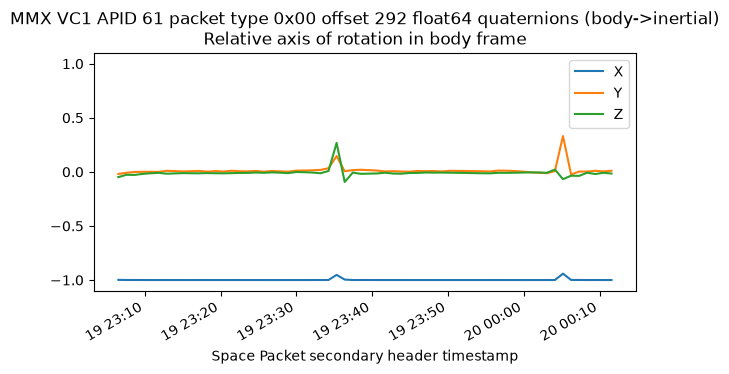

In [170]:
plt.plot(t_quat_sel, u0)
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions (body->inertial)\nRelative axis of rotation in body frame')
plt.xlabel('Space Packet secondary header timestamp')
plt.legend('XYZ')
plt.ylim(-1.1, 1.1);

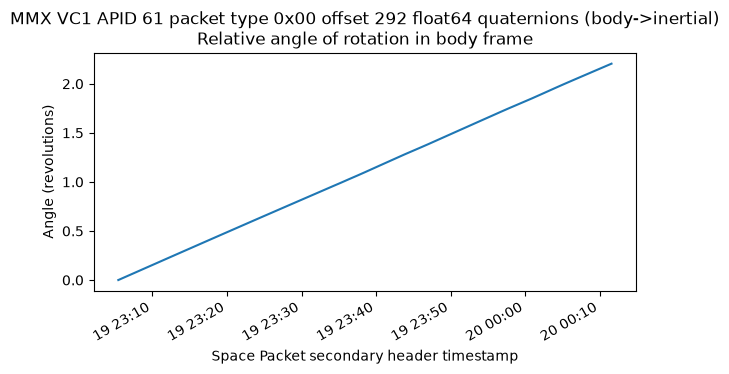

In [171]:
plt.plot(t_quat_sel, theta0 / (2 * np.pi))
plt.ylabel('Angle (revolutions)')
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions (body->inertial)\nRelative angle of rotation in body frame')
plt.xlabel('Space Packet secondary header timestamp');

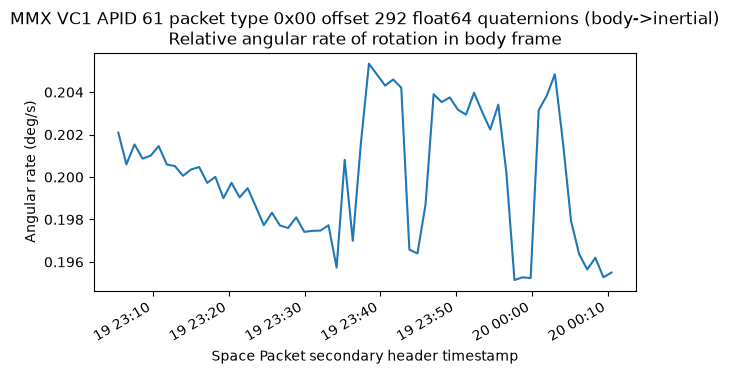

In [172]:
plt.plot(t_quat_sel[:-1], np.diff(theta0) * 360 / (2 * np.pi) / (np.diff(t_quat_sel) / np.timedelta64(1, 's')))
plt.gcf().autofmt_xdate()
plt.ylabel('Angular rate (deg/s)')
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions (body->inertial)\nRelative angular rate of rotation in body frame')
plt.xlabel('Space Packet secondary header timestamp');

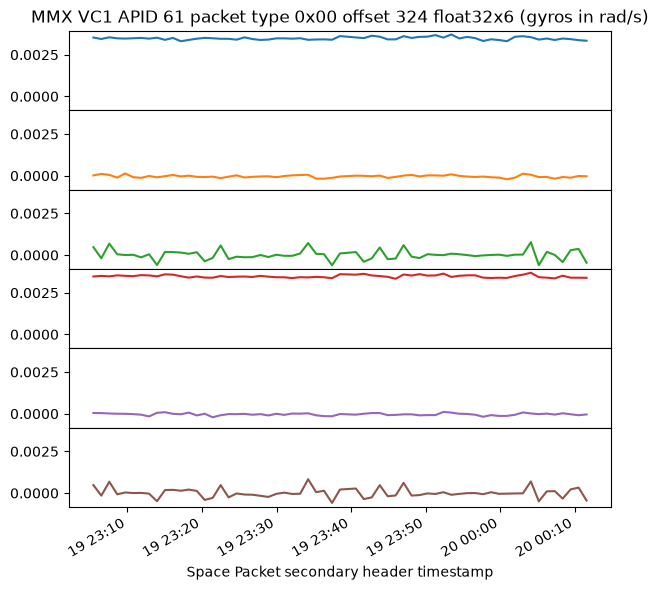

In [173]:
fig, axs = plt.subplots(6, 1, figsize=(7, 7), sharex=True, sharey=True)
for j in range(6):
    axs[j].plot(t_quat_sel,
                vc1_array_by_apid(61, 0)[:, 324+4*j:][:, :4].view('float32').byteswap()[quat_sel], color=f'C{j}')
plt.subplots_adjust(hspace=0)
plt.gcf().autofmt_xdate()
axs[0].set_title('MMX VC1 APID 61 packet type 0x00 offset 324 float32x6 (gyros in rad/s)')
plt.xlabel('Space Packet secondary header timestamp');

In [174]:
gyro_x = np.average(vc1_array_by_apid(61, 0)[:, 324:][:, :4].view('float32').byteswap()[quat_sel].ravel())
np.rad2deg(gyro_x)

np.float32(0.19921155)

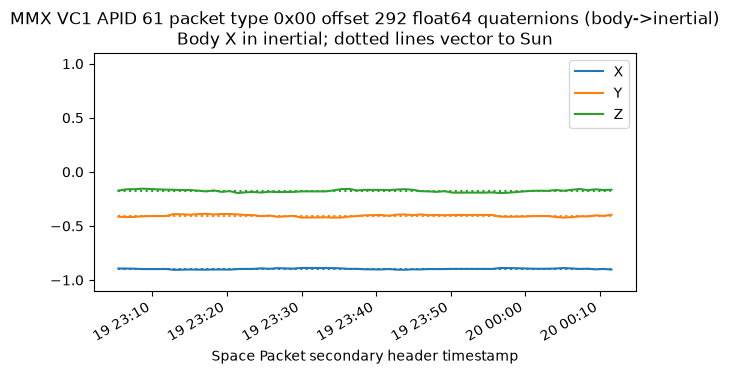

In [175]:
plt.plot(t_quat_sel, q0.apply([1, 0, 0]))
plt.gca().set_prop_cycle(None)
plt.plot([t_quat_sel[0], t_quat_sel[-1]], [-earth_sun_u_interp[0], -earth_sun_u_interp[0]], ':')
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions (body->inertial)\n'
          'Body X in inertial; dotted lines vector to Sun')
plt.xlabel('Space Packet secondary header timestamp')
plt.legend('XYZ')
plt.ylim(-1.1, 1.1);

In [176]:
state_vectors_earth = Horizons(
    id='MMX', location='@399',
    epochs={'start': '2026-10-19T20:30:00', 'stop': '2026-10-20T21:00:00', 'step': '88200'}
).vectors(refplane='earth')
for col in 'xyz':
    state_vectors_earth[col].convert_unit_to('m')
    state_vectors_earth[f'v{col}'].convert_unit_to('m/s')
state_vectors_earth_t = Time(state_vectors_sun['datetime_jd'], format='jd', scale='tdb').utc.datetime64

earth_xyz_interp = np.array([
    np.interp((t_quat_sel2 - state_vectors_sun_t[0]) / np.timedelta64(1, 's'),
              (state_vectors_sun_t - state_vectors_sun_t[0]) / np.timedelta64(1, 's'),
              state_vectors_earth[coord])
    for coord in 'xyz'])
earth_u_interp = earth_xyz_interp / np.sqrt(np.sum(earth_xyz_interp**2, axis=0))

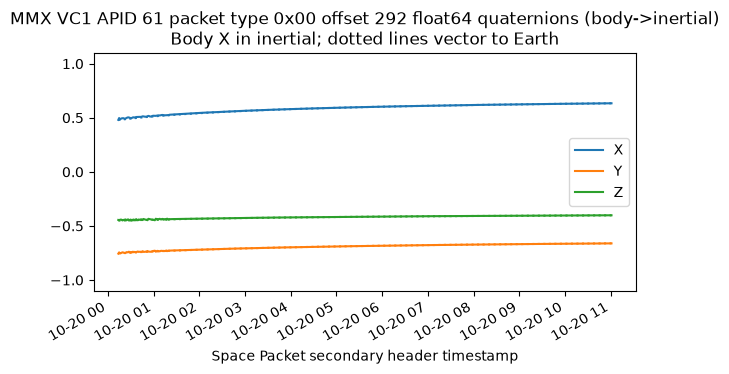

In [177]:
plt.plot(t_quat_sel2, q0_2.apply([1, 0, 0]))
plt.gca().set_prop_cycle(None)
plt.plot(t_quat_sel2, -earth_u_interp.T, ':')
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions (body->inertial)\n'
          'Body X in inertial; dotted lines vector to Earth')
plt.xlabel('Space Packet secondary header timestamp')
plt.legend('XYZ')
plt.ylim(-1.1, 1.1);

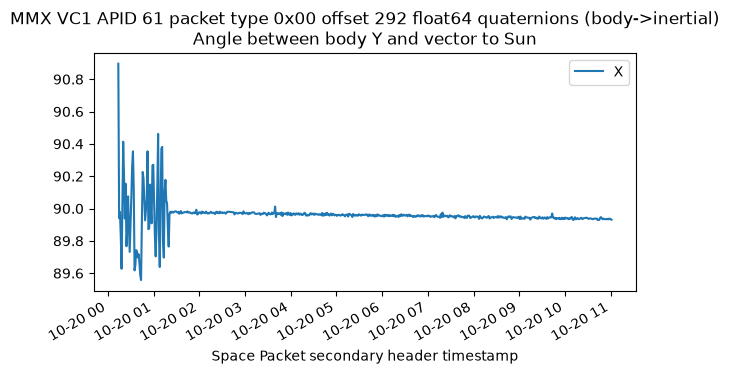

In [178]:
plt.plot(t_quat_sel2, np.rad2deg(np.acos(np.sum(q0_2.apply([0, 1, 0]) * earth_sun_u[:, 0], axis=1))))
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 292 float64 quaternions (body->inertial)\n'
          'Angle between body Y and vector to Sun')
plt.xlabel('Space Packet secondary header timestamp')
plt.legend('XYZ');

In [179]:
quat_sel3 = vc1_apid_packet_type_timestamps(61, 0) >= np.datetime64('2026-10-19T23:05')
t_quat_sel3 = vc1_apid_packet_type_timestamps(61, 0)[quat_sel3]
q0_3 = Rotation.from_quat(apid61_vc1_q0[quat_sel3])

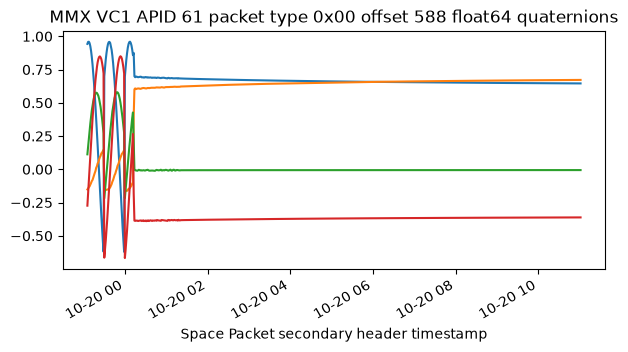

In [180]:
plt.plot(t_quat_sel3, apid61_vc1_q6[quat_sel3])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 588 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

In [181]:
q6 = Rotation.from_quat(apid61_vc1_q6[quat_sel3])

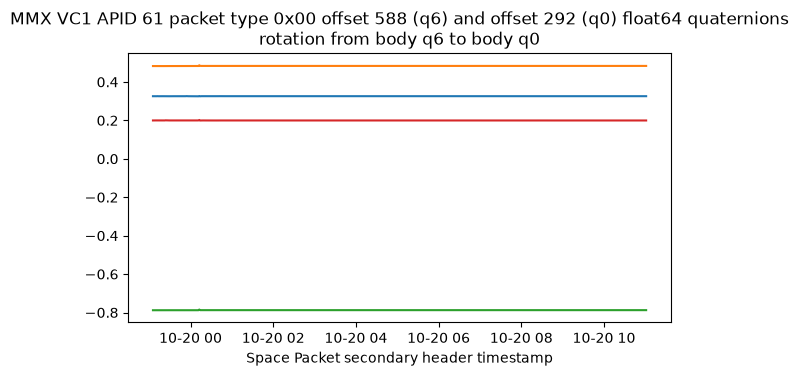

In [182]:
plt.plot(t_quat_sel3, (q0_3.inv() * q6).as_quat(canonical=True))
plt.title('MMX VC1 APID 61 packet type 0x00 offset 588 (q6) and offset 292 (q0) float64 quaternions\nrotation from body q6 to body q0')
plt.xlabel('Space Packet secondary header timestamp');

In [183]:
q0_3[0].inv() * q6[0]

Rotation.from_matrix(array([[-7.08276927e-01,  6.28835339e-01, -3.20795748e-01],
                            [-1.57309146e-04, -4.54567528e-01, -8.90712264e-01],
                            [-7.05934679e-01, -6.30820481e-01,  3.22058613e-01]]))

In [184]:
(q0_3[0].inv() * q6[0]).inv()

Rotation.from_matrix(array([[-7.08276927e-01, -1.57309146e-04, -7.05934679e-01],
                            [ 6.28835339e-01, -4.54567528e-01, -6.30820481e-01],
                            [-3.20795748e-01, -8.90712264e-01,  3.22058613e-01]]))

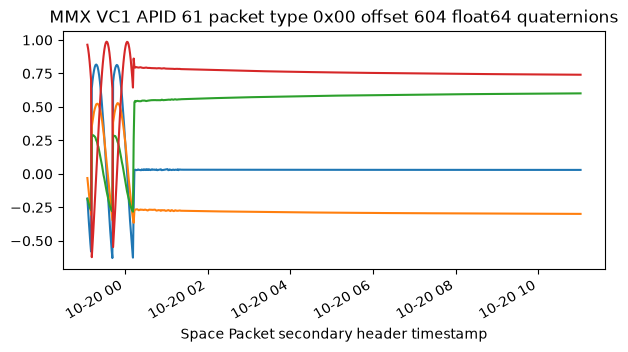

In [185]:
plt.plot(t_quat_sel3, apid61_vc1_q7[quat_sel3])
plt.gcf().autofmt_xdate()
plt.title('MMX VC1 APID 61 packet type 0x00 offset 604 float64 quaternions')
plt.xlabel('Space Packet secondary header timestamp');

In [186]:
q7 = Rotation.from_quat(apid61_vc1_q7[quat_sel3])

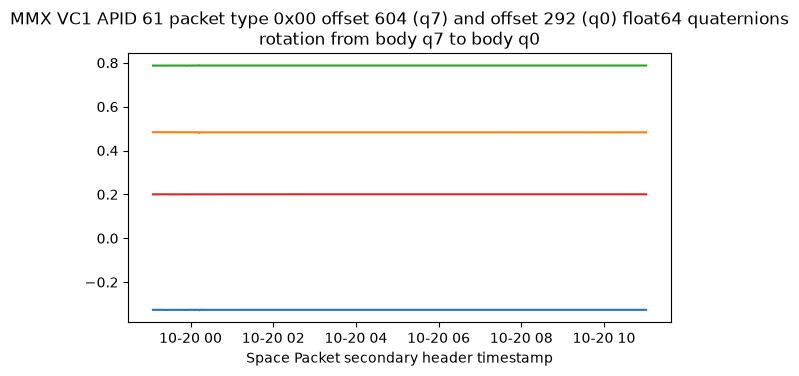

In [187]:
plt.plot(t_quat_sel3, (q0_3.inv() * q7).as_quat(canonical=True))
plt.title('MMX VC1 APID 61 packet type 0x00 offset 604 (q7) and offset 292 (q0) float64 quaternions\nrotation from body q7 to body q0')
plt.xlabel('Space Packet secondary header timestamp');

In [188]:
q0_3[0].inv() * q7[0]

Rotation.from_matrix(array([[-7.06716606e-01, -6.30764273e-01, -3.20449796e-01],
                            [-5.64353335e-04, -4.52431924e-01,  8.91798764e-01],
                            [-7.07496516e-01,  6.30429842e-01,  3.19385180e-01]]))

In [189]:
(q0_3[0].inv() * q7[0]).inv()

Rotation.from_matrix(array([[-7.06716606e-01, -5.64353335e-04, -7.07496516e-01],
                            [-6.30764273e-01, -4.52431924e-01,  6.30429842e-01],
                            [-3.20449796e-01,  8.91798764e-01,  3.19385180e-01]]))

In [190]:
q6[0].inv() * q7[0]

Rotation.from_matrix(array([[ 9.99997480e-01,  1.78466404e-03,  1.36183386e-03],
                            [ 2.15145326e-03, -5.88674060e-01, -8.08367628e-01],
                            [-6.40988371e-04,  8.08368521e-01, -5.88676417e-01]]))

In [191]:
(q6[0].inv() * q7[0]).inv()

Rotation.from_matrix(array([[ 9.99997480e-01,  2.15145326e-03, -6.40988371e-04],
                            [ 1.78466404e-03, -5.88674060e-01,  8.08368521e-01],
                            [ 1.36183386e-03, -8.08367628e-01, -5.88676417e-01]]))

## VC 62

VC 62 frames have the transfer frame data field full of zeros except for the last 8 bytes. In these 8 bytes, the first 5 are a CCSDS CUC timestamp in the same format as the Space Packet timestamps. The next byte is always a zero, and I don't know what are the last 2 bytes.

In [192]:
assert np.all(frames[vcid == 62][:, ccsds.AOSPrimaryHeader.sizeof():-12] == 0)

In [193]:
vc62_data = frames[vcid == 62][:, -12:-4]

In [194]:
assert np.all(vc62_data[:, 0] == 0b00101100)
assert np.all(vc62_data[:, 5] == 0)

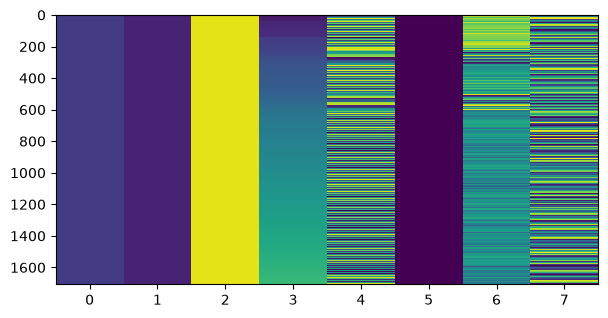

In [195]:
plt.imshow(vc62_data, aspect='auto', interpolation='none')

In [196]:
vc62_timestamps = ((vc62_data[:, 1:5].view('uint32').byteswap().ravel() * 1e9) * np.timedelta64(1, 'ns')
                   + np.datetime64('2013-01-01T00:00:00'))

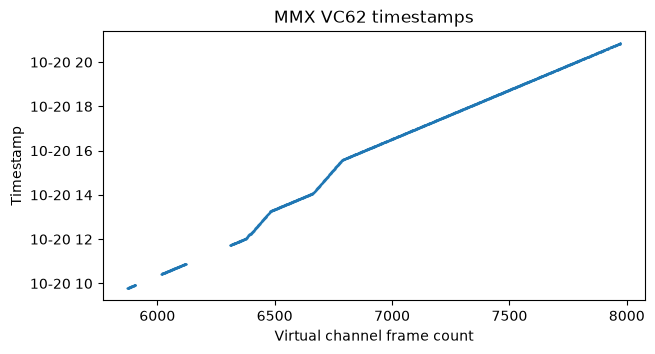

In [197]:
plt.plot(vcfc[vcid == 62], vc62_timestamps, '.', markersize=1)
plt.title('MMX VC62 timestamps')
plt.ylabel('Timestamp')
plt.xlabel('Virtual channel frame count');